In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

plt.style.use('ggplot')
sns.set_palette("muted")

input_pairs = [
    {
        "model_name": "CFN_Ablation_IaCGOD",
        "result_file": "../results/CFN_Ablation_IaCGOD/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_IaCGOD.csv"
    },
    {
        "model_name": "CFN_Ablation_NoDenseRAG",
        "result_file": "../results/CFN_Ablation_NoDenseRAG/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_NoDenseRAG.csv"
    },
    {
        "model_name": "CFN_Ablation_NoGraphRAG",
        "result_file": "../results/CFN_Ablation_NoGraphRAG/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_NoGraphRAG.csv"
    },
    {
        "model_name": "CFN_Ablation_NoPlanner",
        "result_file": "../results/CFN_Ablation_NoPlanner/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_NoPlanner.csv"
    },
    {
        "model_name": "CFN_Ablation_OpenCodeRetriever",
        "result_file": "../results/CFN_Ablation_OpenCodeRetriever/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_OpenCodeRetriever.csv"
    },
    {
        "model_name": "CFN_Ablation_TrivyAllSeverities",
        "result_file": "../results/CFN_Ablation_TrivyAllSeverities/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_TrivyAllSeverities.csv"
    },
    {
        "model_name": "CFN_DPIaCEval_o3mini_DeployOnly",
        "result_file": "../results/CFN_DPIaCEval_o3mini_DeployOnly/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_DPIaCEval_o3mini_DeployOnly.csv"
    },
    {
        "model_name": "CFN_RealAWS_DSV4F",
        "result_file": "../results/CFN_RealAWS_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_DSV4F_DeployOnly_L345",
        "result_file": "../results/CFN_RealAWS_DSV4F_DeployOnly_L345/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_DSV4F_DeployOnly_L345.csv"
    },
    {
        "model_name": "CFN_RealAWS_GLM53F",
        "result_file": "../results/CFN_RealAWS_GLM53F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_GLM53F.csv"
    },
    {
        "model_name": "CFN_RealAWS_IaCGen_GLM53F",
        "result_file": "../results/CFN_RealAWS_IaCGen_GLM53F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_IaCGen_GLM53F.csv"
    },
    {
        "model_name": "CFN_RealAWS_Gemini36F_L345",
        "result_file": "../results/CFN_RealAWS_Gemini36F_L345/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_Gemini36F_L345.csv"
    },
    {
        "model_name": "CFN_RealAWS_Gemini38F",
        "result_file": "../results/CFN_RealAWS_Gemini38F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_Gemini38F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OpenCode_DSV4F",
        "result_file": "../results/CFN_RealAWS_OpenCode_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_OpenCode_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_Opus55",
        "result_file": "../results/CFN_RealAWS_Opus55/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_Opus55.csv"
    },
    {
        "model_name": "TF_Ablation_IaCGOD",
        "result_file": "../results/TF_Ablation_IaCGOD/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_IaCGOD.csv"
    },
    {
        "model_name": "TF_Ablation_NoDenseRAG",
        "result_file": "../results/TF_Ablation_NoDenseRAG/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_NoDenseRAG.csv"
    },
    {
        "model_name": "TF_Ablation_NoGraphRAG",
        "result_file": "../results/TF_Ablation_NoGraphRAG/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_NoGraphRAG.csv"
    },
    {
        "model_name": "TF_Ablation_NoPlanner",
        "result_file": "../results/TF_Ablation_NoPlanner/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_NoPlanner.csv"
    },
    {
        "model_name": "TF_Ablation_OpenCodeRetriever",
        "result_file": "../results/TF_Ablation_OpenCodeRetriever/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_OpenCodeRetriever.csv"
    },
    {
        "model_name": "TF_Ablation_TrivyAllSeverities",
        "result_file": "../results/TF_Ablation_TrivyAllSeverities/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_TrivyAllSeverities.csv"
    },
    {
        "model_name": "TF_IaCEval_DSV4F_LintOnly",
        "result_file": "../results/TF_IaCEval_DSV4F_LintOnly/results_final.csv",
        "audit_file": "result/final/Trivy_TF_IaCEval_DSV4F_LintOnly.csv"
    },
    {
        "model_name": "TF_RealAWS_DSV4F",
        "result_file": "../results/TF_RealAWS_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_DSV4F.csv"
    },
    {
        "model_name": "TF_RealAWS_GLM53F",
        "result_file": "../results/TF_RealAWS_GLM53F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_GLM53F.csv"
    },
    {
        "model_name": "TF_RealAWS_Gemini38F",
        "result_file": "../results/TF_RealAWS_Gemini38F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_Gemini38F.csv"
    },
    {
        "model_name": "TF_RealAWS_OpenCode_DSV4F",
        "result_file": "../results/TF_RealAWS_OpenCode_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_OpenCode_DSV4F.csv"
    },
    {
        "model_name": "TF_RealAWS_Opus55",
        "result_file": "../results/TF_RealAWS_Opus55/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_Opus55.csv"
    },
        {
        "model_name": "TF_RealAWS_OneShot_GLM53F",
        "result_file": "../results/TF_RealAWS_OneShot_GLM53F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_OneShot_GLM53F.csv"
    },
        {
        "model_name": "TF_RealAWS_ZeroShot_Opus55",
        "result_file": "../results/TF_RealAWS_ZeroShot_Opus55/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_ZeroShot_Opus55.csv"
    },
    {
        "model_name": "CFN_Ablation_NoQueryRewrite",
        "result_file": "../results/CFN_Ablation_NoQueryRewrite/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_NoQueryRewrite.csv"
    },
    {
        "model_name": "CFN_Ablation_NoRemediator",
        "result_file": "../results/CFN_Ablation_NoRemediator/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_Ablation_NoRemediator.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_DSV4F",
        "result_file": "../results/CFN_RealAWS_OneShot_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_OneShot_DSV4F.csv"
    },
    {
        "model_name": "TF_Ablation_NoQueryRewrite",
        "result_file": "../results/TF_Ablation_NoQueryRewrite/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_NoQueryRewrite.csv"
    },
    {
        "model_name": "TF_Ablation_NoRemediator",
        "result_file": "../results/TF_Ablation_NoRemediator/results_final.csv",
        "audit_file": "result/final/Trivy_TF_Ablation_NoRemediator.csv"
    },
    {
        "model_name": "TF_RealAWS_OneShot_DSV4F",
        "result_file": "../results/TF_RealAWS_OneShot_DSV4F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_OneShot_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_Gemini38F",
        "result_file": "../results/CFN_RealAWS_OneShot_Gemini38F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_OneShot_Gemini38F.csv"
    },
    {
        "model_name": "TF_RealAWS_OneShot_Gemini38F",
        "result_file": "../results/TF_RealAWS_OneShot_Gemini38F/results_final.csv",
        "audit_file": "result/final/Trivy_TF_RealAWS_OneShot_Gemini38F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_GLM53F",
        "result_file": "../results/CFN_RealAWS_OneShot_GLM53F/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_OneShot_GLM53F.csv"
    },
        {
        "model_name": "CFN_RealAWS_ZeroShot_Opus55",
        "result_file": "../results/CFN_RealAWS_ZeroShot_Opus55/results_final.csv",
        "audit_file": "result/final/Trivy_CFN_RealAWS_ZeroShot_Opus55.csv"
    },
]

policy_map_file = "Data/trivy_enriched.csv"

In [3]:
policy_df = pd.read_csv(policy_map_file)

policy_mapping = {}
for _, row in policy_df.iterrows():
    check_id = str(row['check_id']).strip()
    check_name = str(row['check_name']).strip()
    check_severity = str(row['severity']).strip()
    
    policy_mapping[check_id] = f"[{check_severity}] {check_name}"
    
    if check_id.startswith("AVD-"):
        base_id = check_id.replace("AVD-", "")
        policy_mapping[base_id] = f"[{check_severity}] {check_name}"

print(f"Loaded {len(policy_mapping)} policy mapping rules.")

Loaded 1465 policy mapping rules.


In [4]:
merged_dataframes = {}

for pair in input_pairs:
    model = pair["model_name"]
    res_df = pd.read_csv(pair["result_file"])
    audit_df = pd.read_csv(pair["audit_file"])
    
    merged_df = pd.merge(res_df, audit_df, on="run_id", how="left")
    
    merged_df["Policy Pass Rate"] = merged_df["total_passed"] / merged_df["total_checks"]
    
    merged_dataframes[model] = merged_df
    print(f"Successfully processed and merged data for: {model}")

Successfully processed and merged data for: CFN_Ablation_IaCGOD
Successfully processed and merged data for: CFN_Ablation_NoDenseRAG
Successfully processed and merged data for: CFN_Ablation_NoGraphRAG
Successfully processed and merged data for: CFN_Ablation_NoPlanner
Successfully processed and merged data for: CFN_Ablation_OpenCodeRetriever
Successfully processed and merged data for: CFN_Ablation_TrivyAllSeverities
Successfully processed and merged data for: CFN_DPIaCEval_o3mini_DeployOnly
Successfully processed and merged data for: CFN_RealAWS_DSV4F
Successfully processed and merged data for: CFN_RealAWS_DSV4F_DeployOnly_L345
Successfully processed and merged data for: CFN_RealAWS_GLM53F
Successfully processed and merged data for: CFN_RealAWS_IaCGen_GLM53F


Successfully processed and merged data for: CFN_RealAWS_Gemini36F_L345


Successfully processed and merged data for: CFN_RealAWS_Gemini38F
Successfully processed and merged data for: CFN_RealAWS_OpenCode_DSV4F
Successfully processed and merged data for: CFN_RealAWS_Opus55
Successfully processed and merged data for: TF_Ablation_IaCGOD
Successfully processed and merged data for: TF_Ablation_NoDenseRAG
Successfully processed and merged data for: TF_Ablation_NoGraphRAG
Successfully processed and merged data for: TF_Ablation_NoPlanner
Successfully processed and merged data for: TF_Ablation_OpenCodeRetriever
Successfully processed and merged data for: TF_Ablation_TrivyAllSeverities


Successfully processed and merged data for: TF_IaCEval_DSV4F_LintOnly


Successfully processed and merged data for: TF_RealAWS_DSV4F
Successfully processed and merged data for: TF_RealAWS_GLM53F
Successfully processed and merged data for: TF_RealAWS_Gemini38F
Successfully processed and merged data for: TF_RealAWS_OpenCode_DSV4F


Successfully processed and merged data for: TF_RealAWS_Opus55
Successfully processed and merged data for: TF_RealAWS_OneShot_GLM53F
Successfully processed and merged data for: TF_RealAWS_ZeroShot_Opus55
Successfully processed and merged data for: CFN_Ablation_NoQueryRewrite
Successfully processed and merged data for: CFN_Ablation_NoRemediator
Successfully processed and merged data for: CFN_RealAWS_OneShot_DSV4F
Successfully processed and merged data for: TF_Ablation_NoQueryRewrite
Successfully processed and merged data for: TF_Ablation_NoRemediator
Successfully processed and merged data for: TF_RealAWS_OneShot_DSV4F


Successfully processed and merged data for: CFN_RealAWS_OneShot_Gemini38F
Successfully processed and merged data for: TF_RealAWS_OneShot_Gemini38F
Successfully processed and merged data for: CFN_RealAWS_OneShot_GLM53F
Successfully processed and merged data for: CFN_RealAWS_ZeroShot_Opus55


In [5]:
import ipywidgets as widgets
from IPython.display import display

_all_models = list(merged_dataframes.keys())
model_selector = widgets.SelectMultiple(
    options=_all_models,
    value=tuple(_all_models),
    description='Models:',
    rows=min(len(_all_models), 8),
    layout=widgets.Layout(width='420px'),
)
display(widgets.HTML(
    '<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every '
    'comparison chart below — defaults to all models):'
))
display(model_selector)

def get_selected_models():
    selected = set(model_selector.value)
    ordered = [m for m in _all_models if m in selected]
    return ordered if ordered else list(_all_models)

HTML(value='<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every comparison chart below — …

SelectMultiple(description='Models:', index=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…

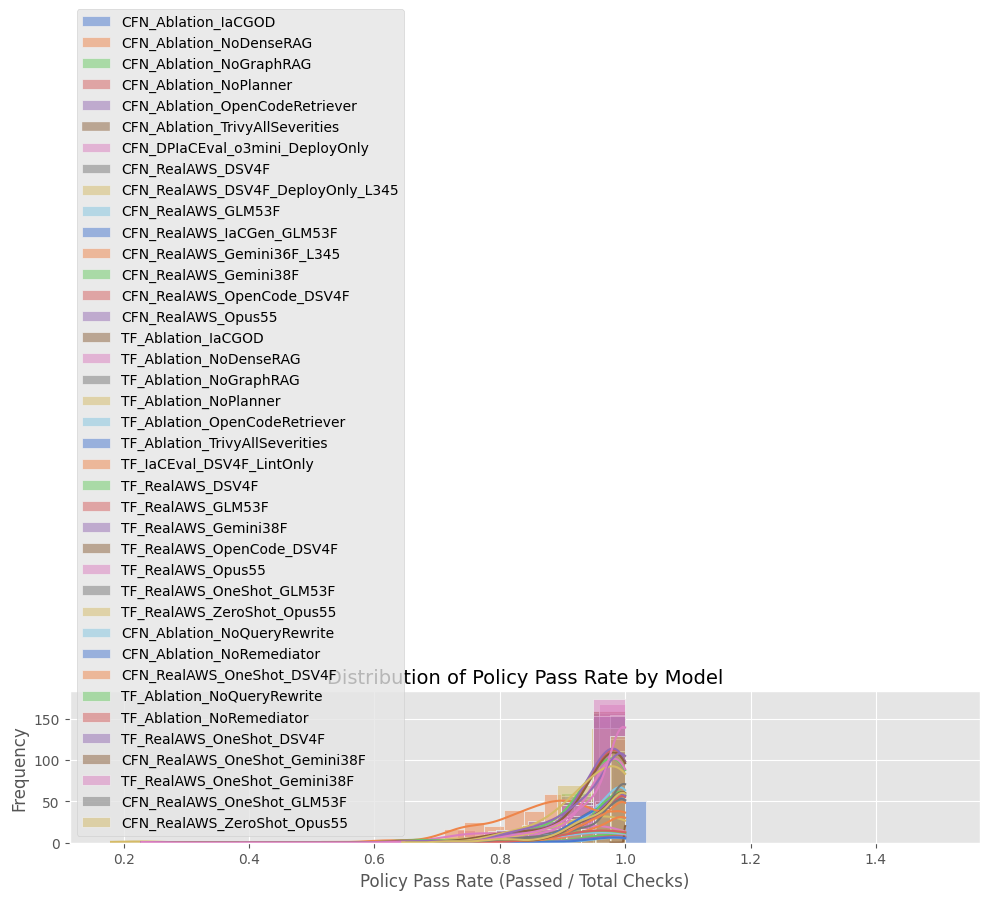

None

In [6]:
def _plot_policy_pass_rate_distribution(selected_models):
    plt.figure(figsize=(10, 6))

    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        valid_rates = df["Policy Pass Rate"].dropna()
        sns.histplot(valid_rates, kde=True, label=model_name, bins=15, alpha=0.5)

    plt.title("Distribution of Policy Pass Rate by Model", fontsize=14)
    plt.xlabel("Policy Pass Rate (Passed / Total Checks)", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

_out_policy_pass_rate_distribution = widgets.interactive_output(
    _plot_policy_pass_rate_distribution, {'selected_models': model_selector}
)
display(_out_policy_pass_rate_distribution)

In [7]:
def _plot_severity_totals(selected_models):
    severity_cols = ['severity_critical', 'severity_high', 'severity_medium', 'severity_low']
    severity_data = []

    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        for col in severity_cols:
            if col in df.columns:
                total = df[col].sum()
                clean_label = col.replace("severity_", "").capitalize()
                severity_data.append({"Model": model_name, "Severity": clean_label, "Count": total})

    sev_df = pd.DataFrame(severity_data)

    if not sev_df.empty:
        plt.figure(figsize=(10, 6))
        sns.barplot(data=sev_df, x="Severity", y="Count", hue="Model", palette="Reds_r")
        plt.title("Total Identified Severities by Level", fontsize=14)
        plt.xlabel("Severity Level", fontsize=12)
        plt.ylabel("Total Count", fontsize=12)
        plt.tight_layout()
        plt.show()
    else:
        print("No severity columns found to plot.")

_out_severity_totals = widgets.interactive_output(
    _plot_severity_totals, {'selected_models': model_selector}
)
display(_out_severity_totals)

No severity columns found to plot.


None

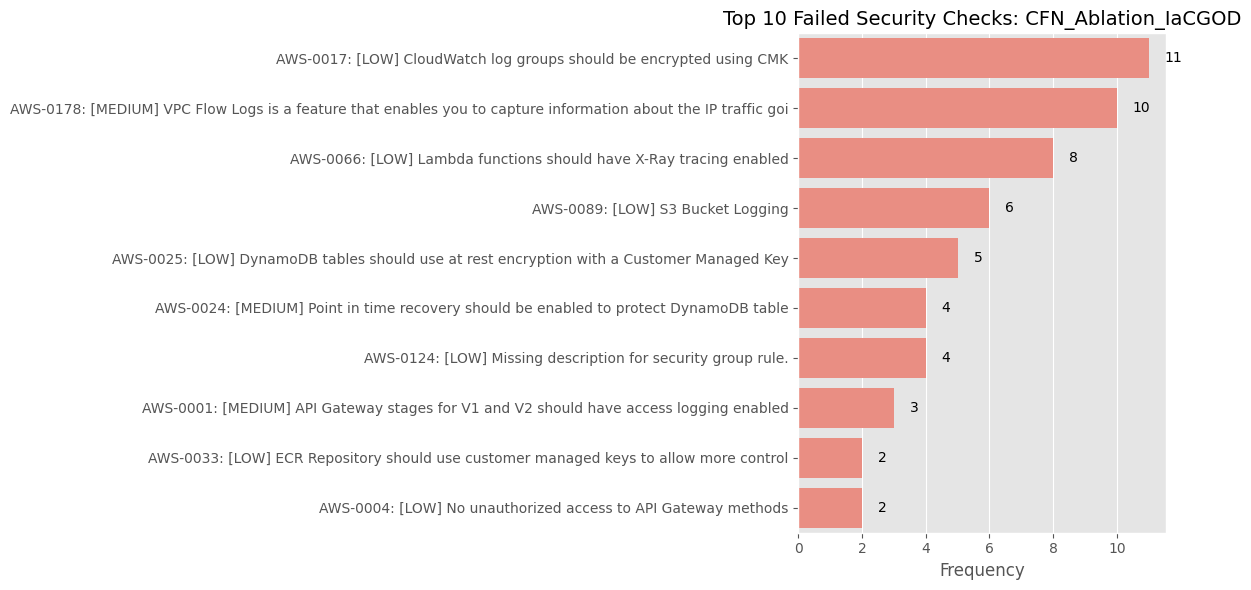

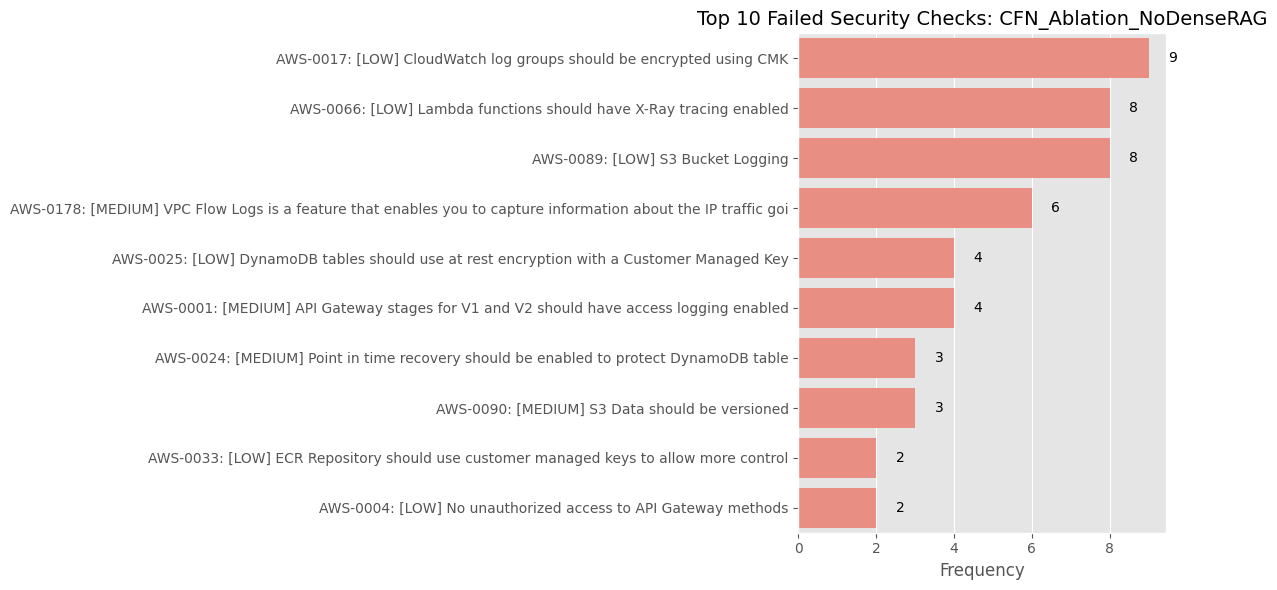

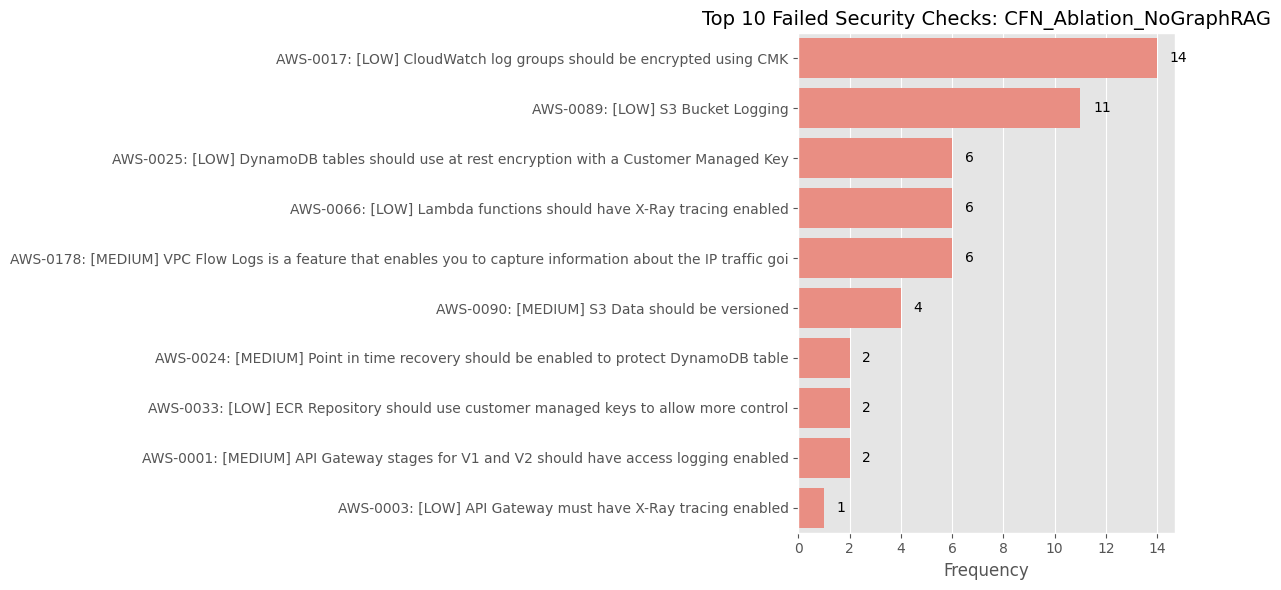

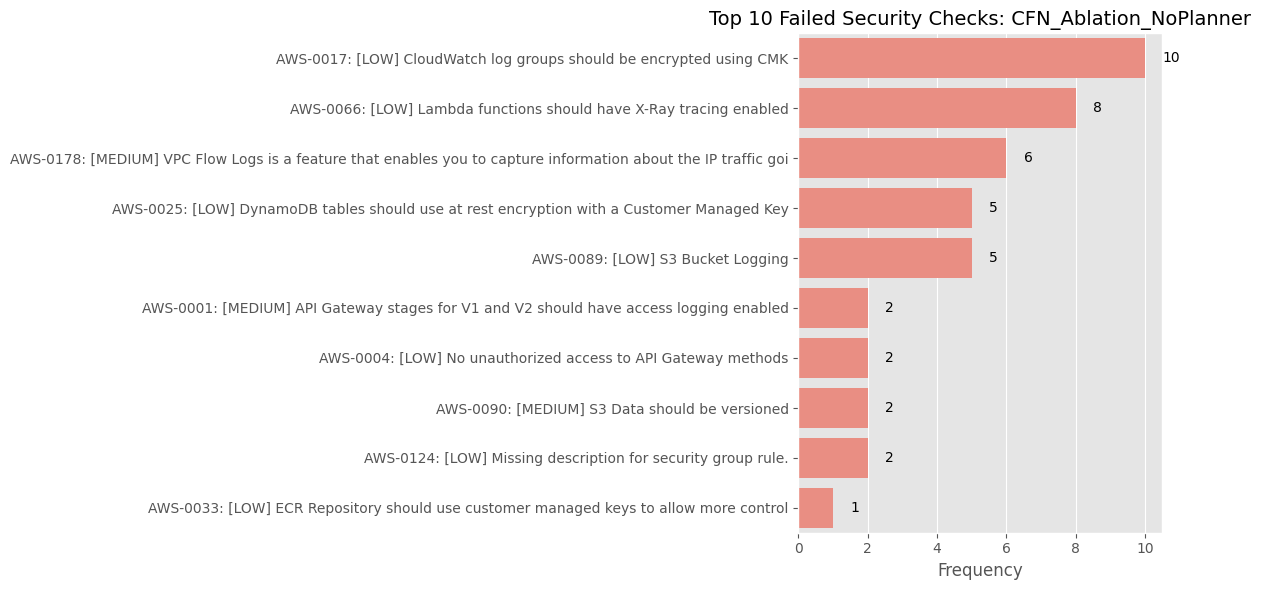

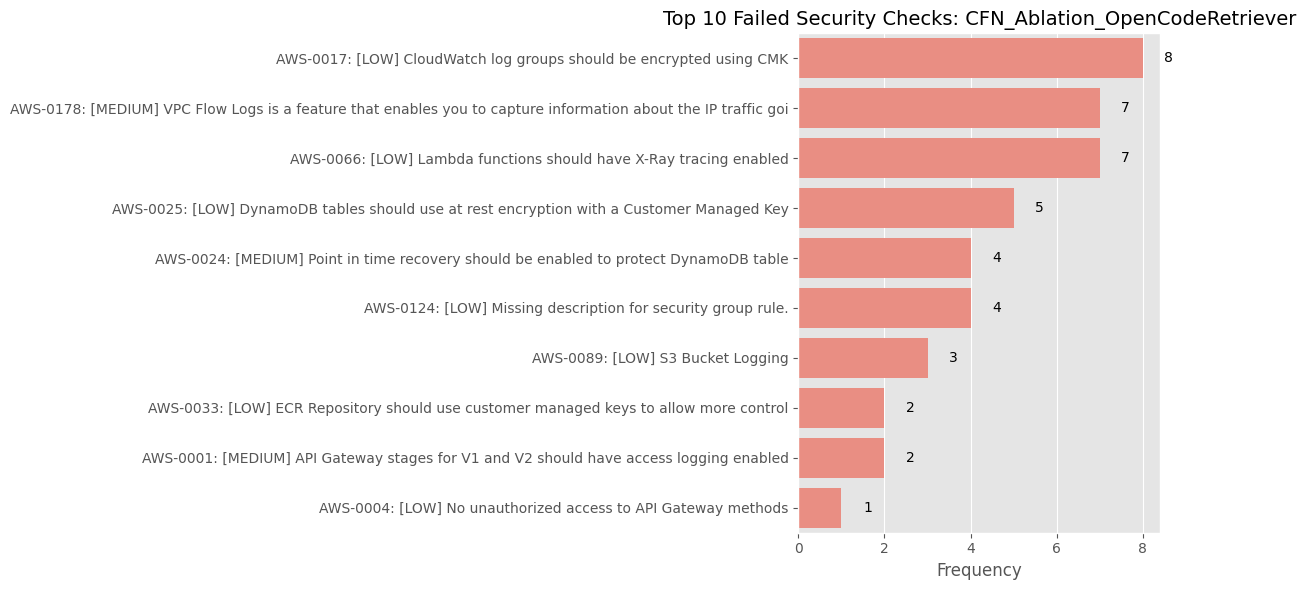

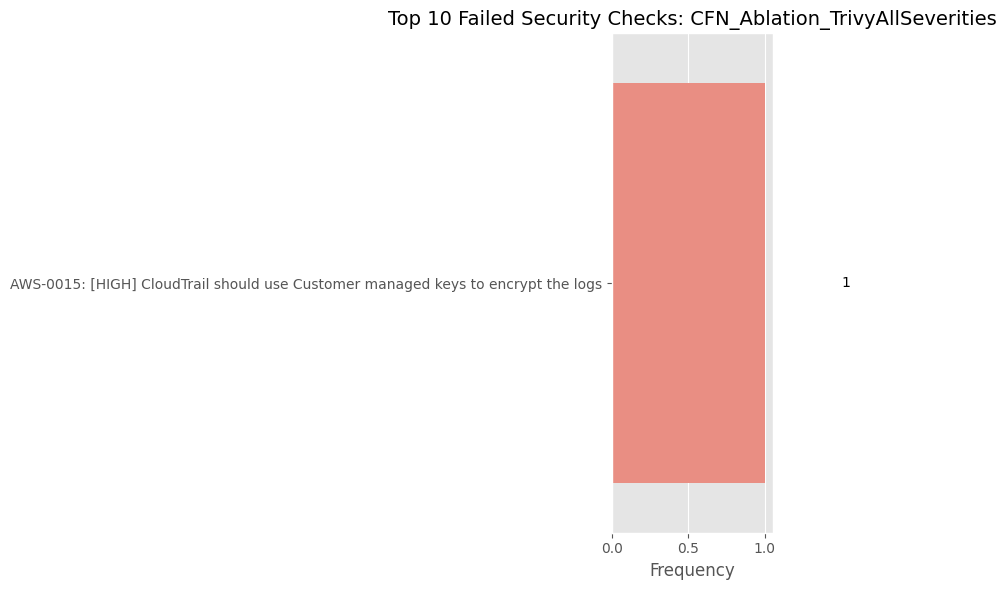

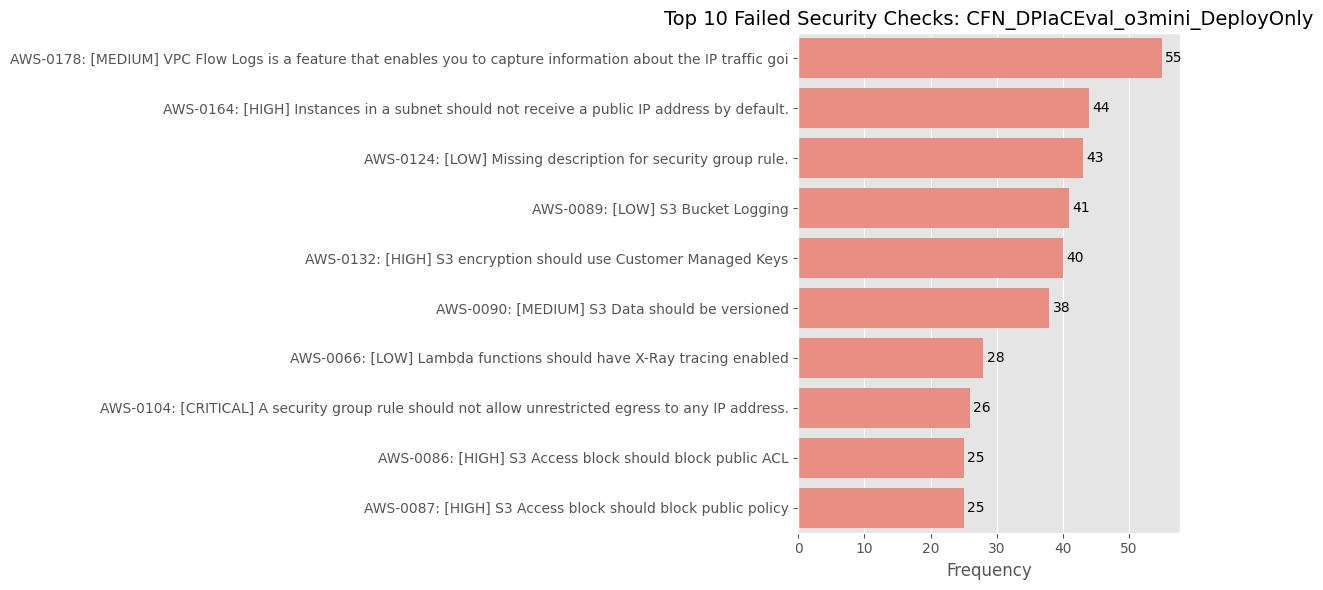

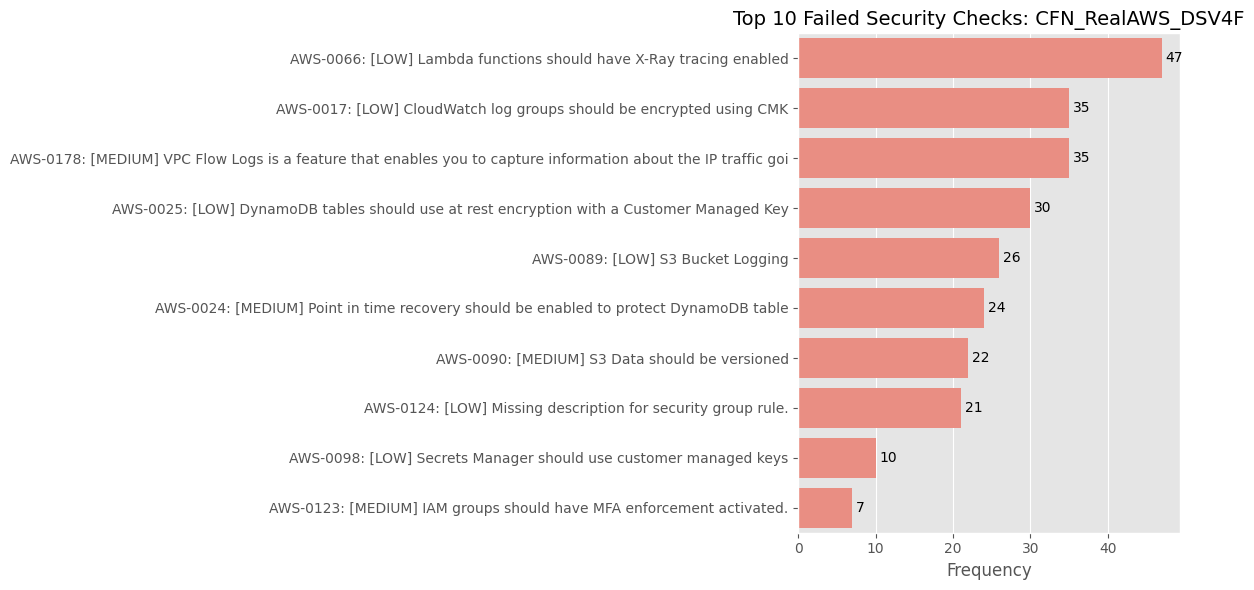

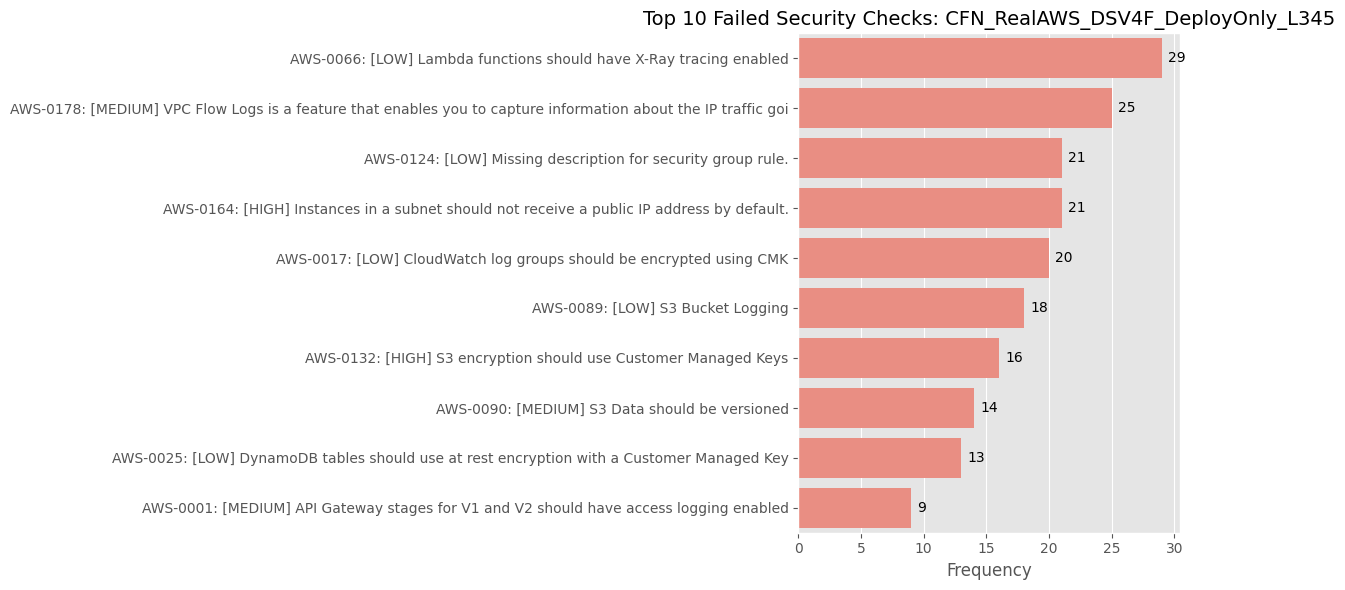

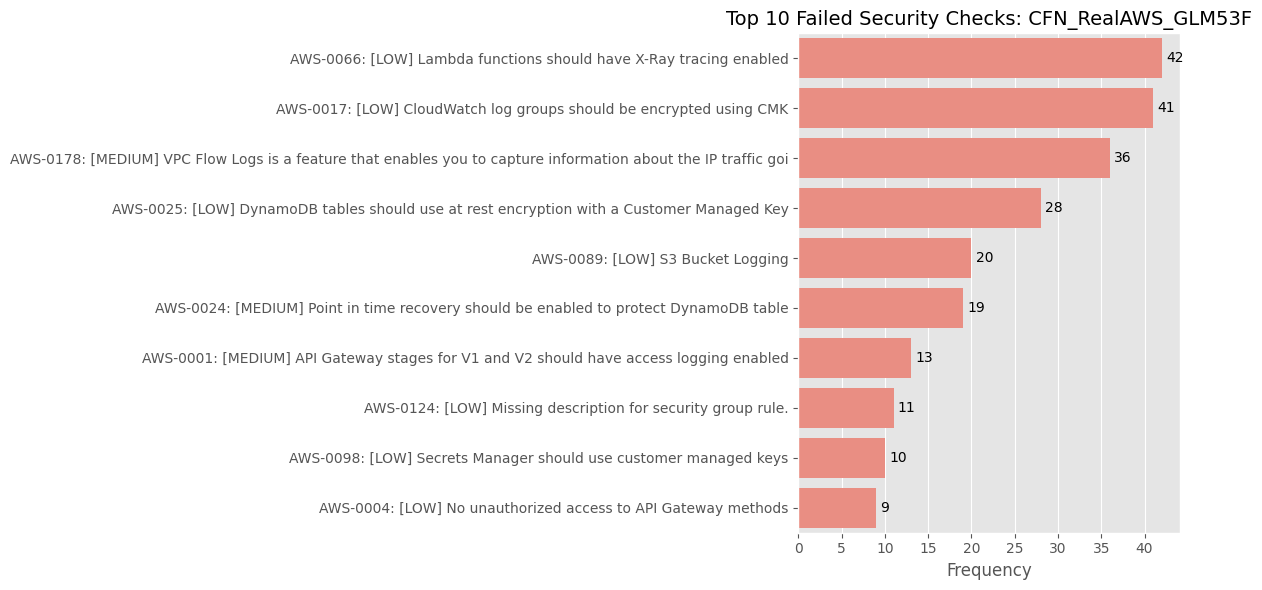

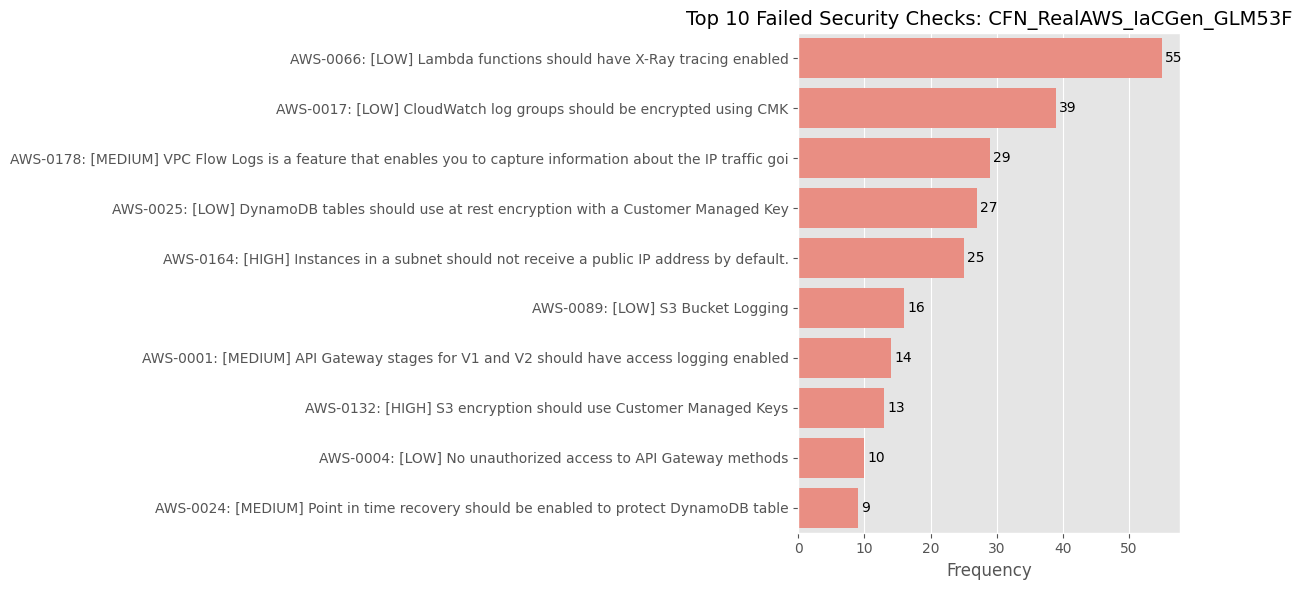

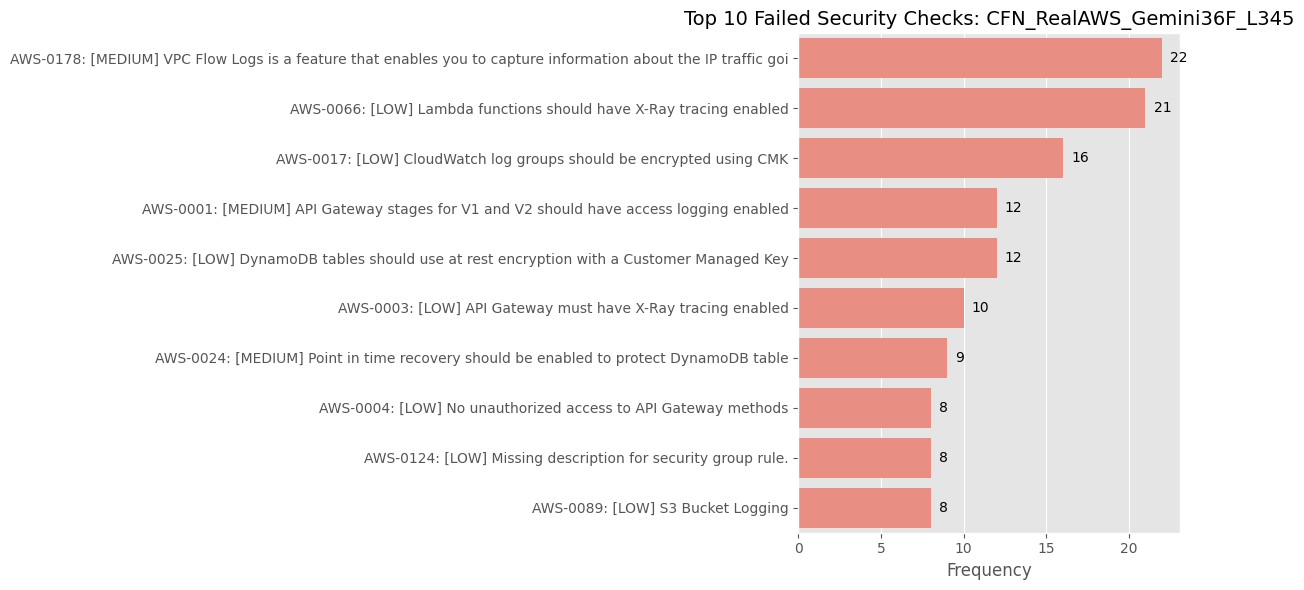

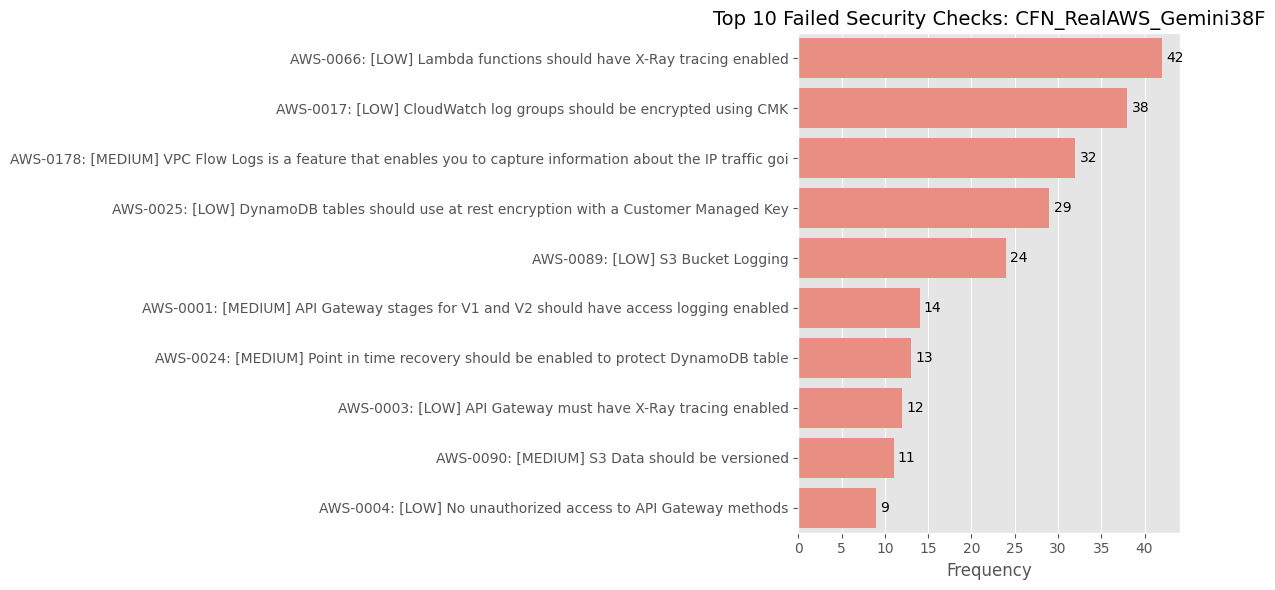

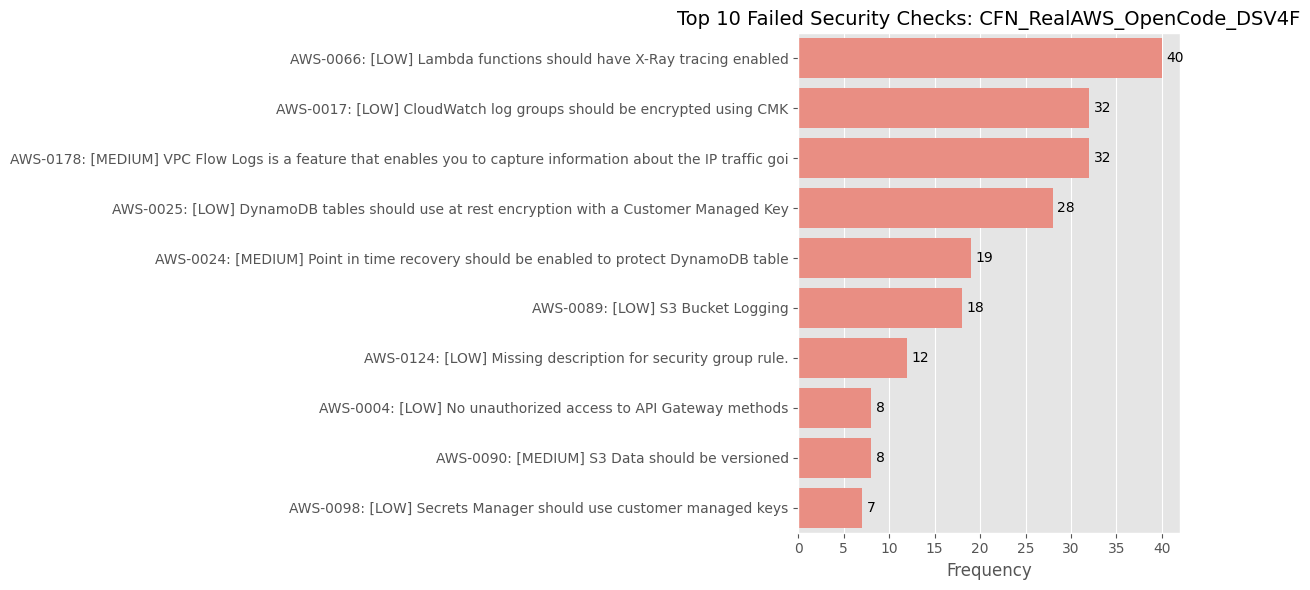

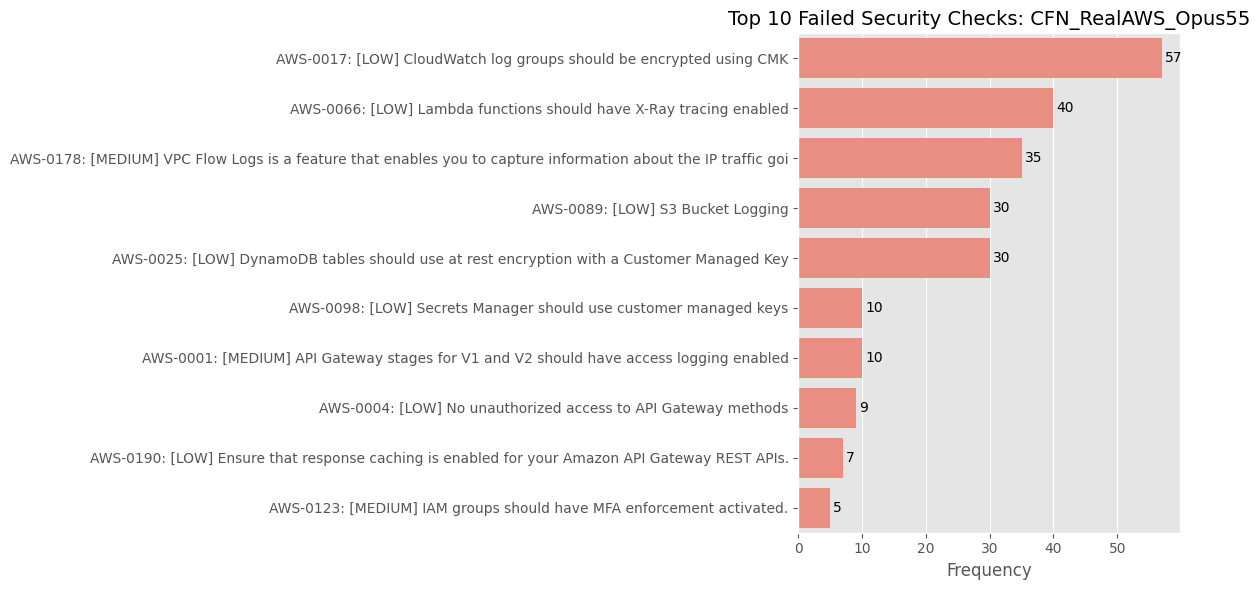

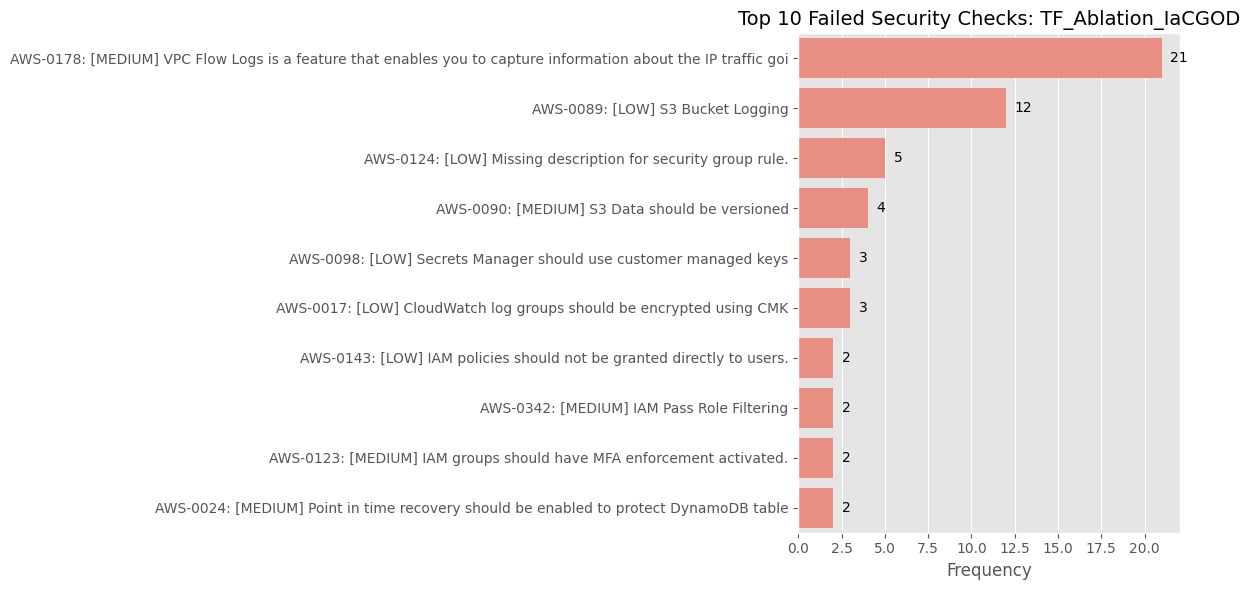

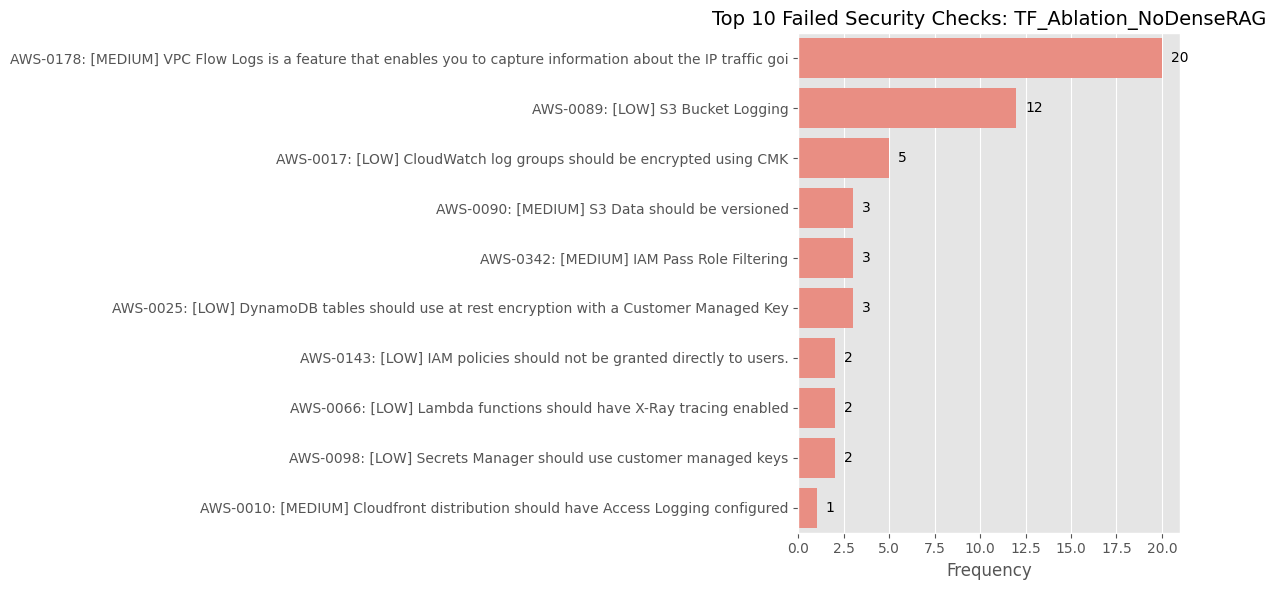

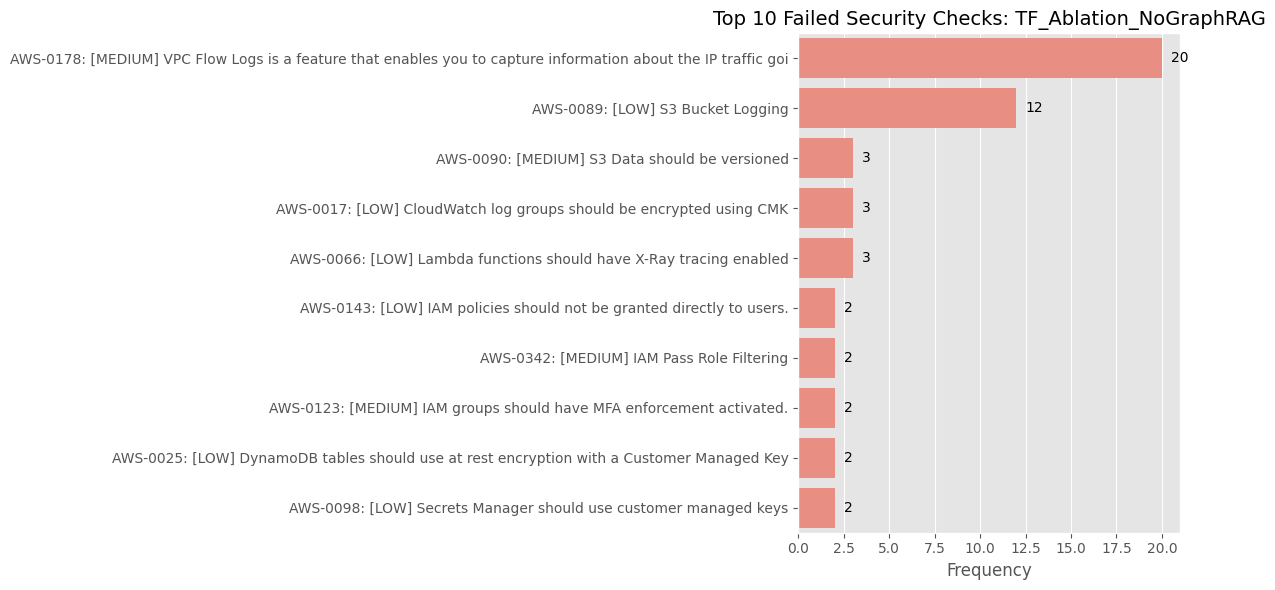

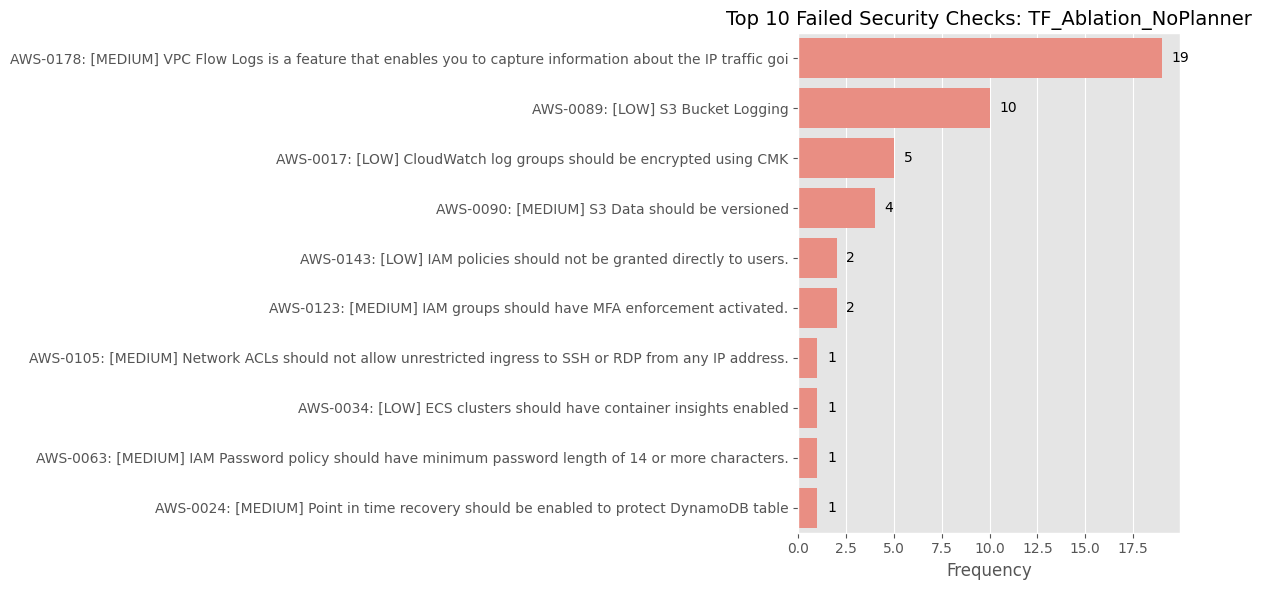

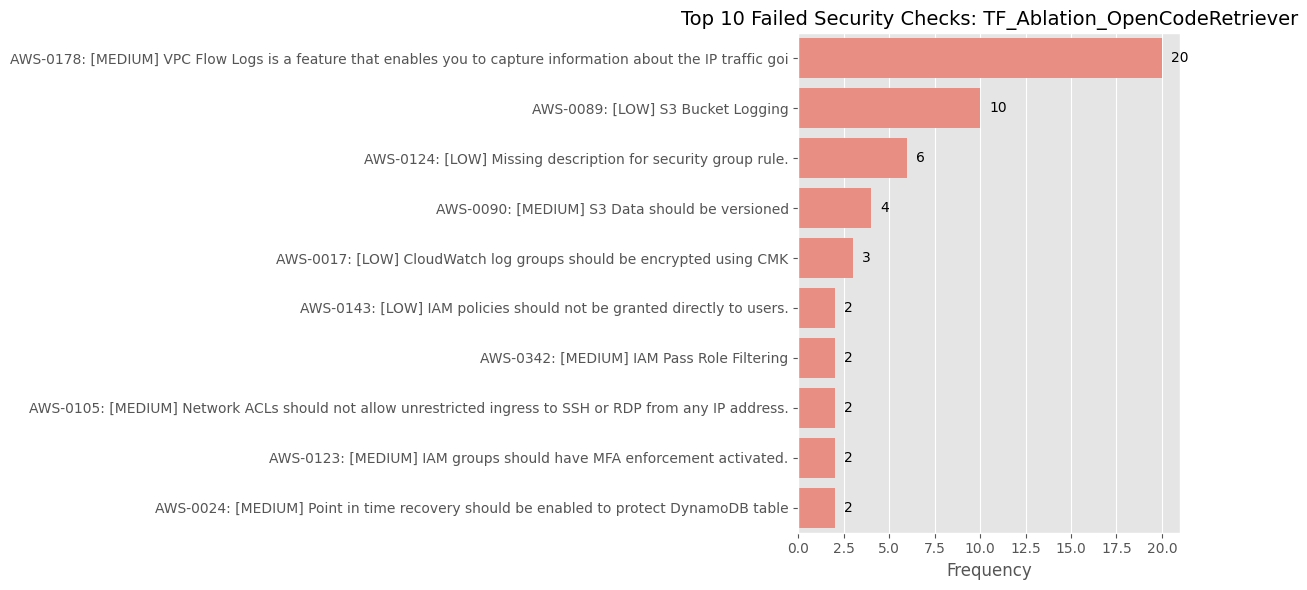

No failed checks found for model: TF_Ablation_TrivyAllSeverities


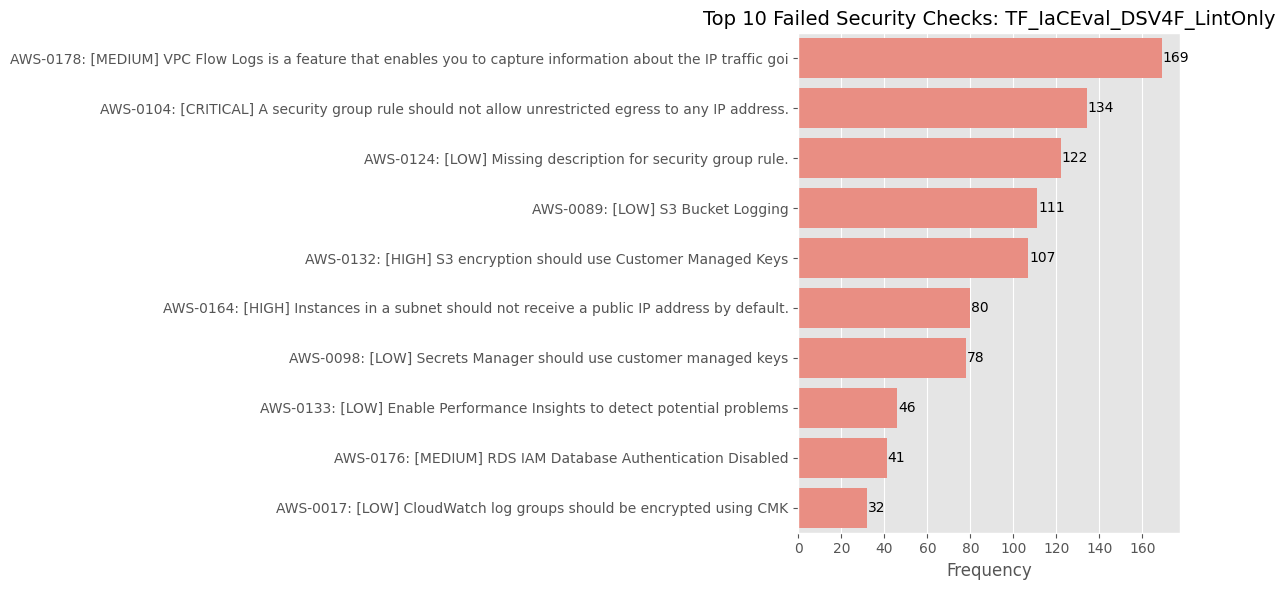

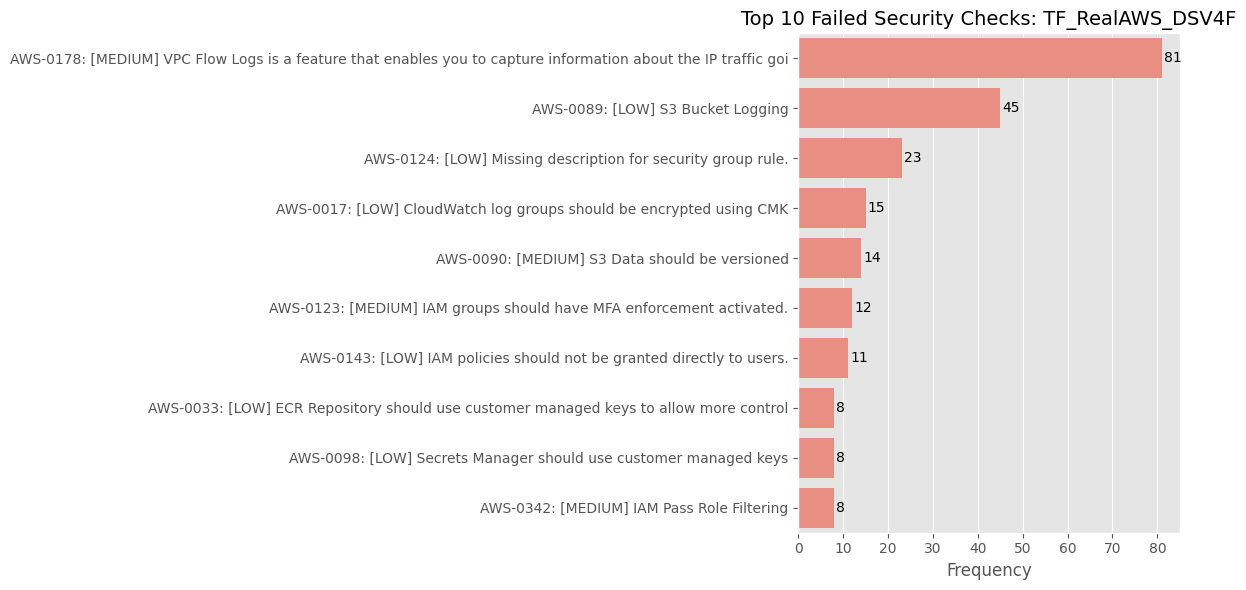

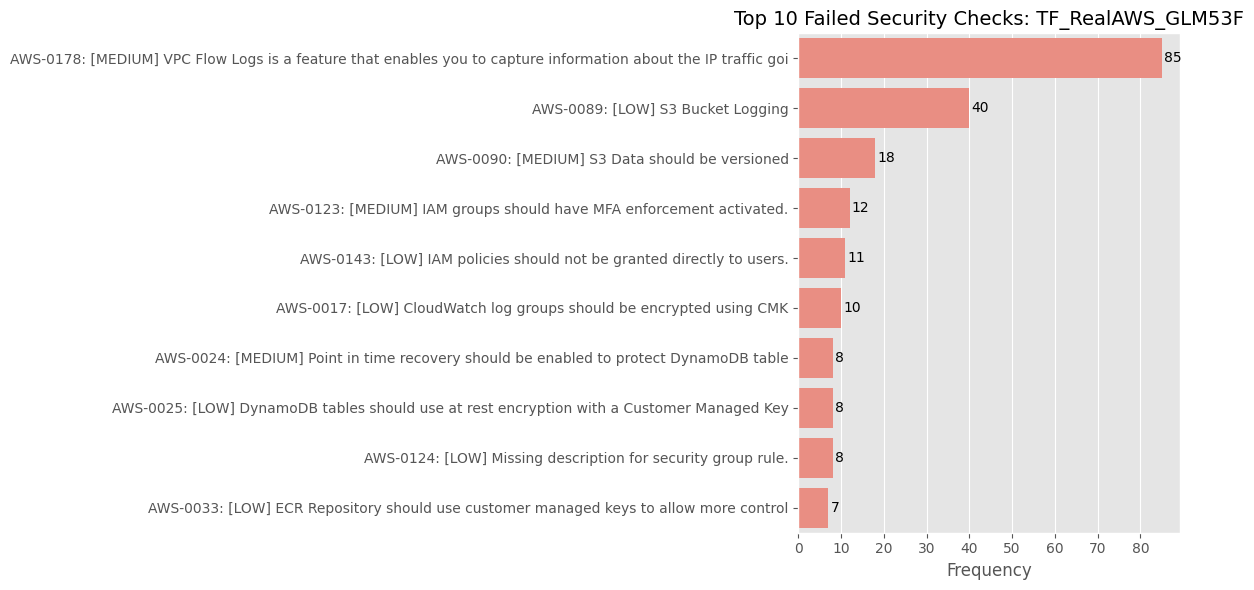

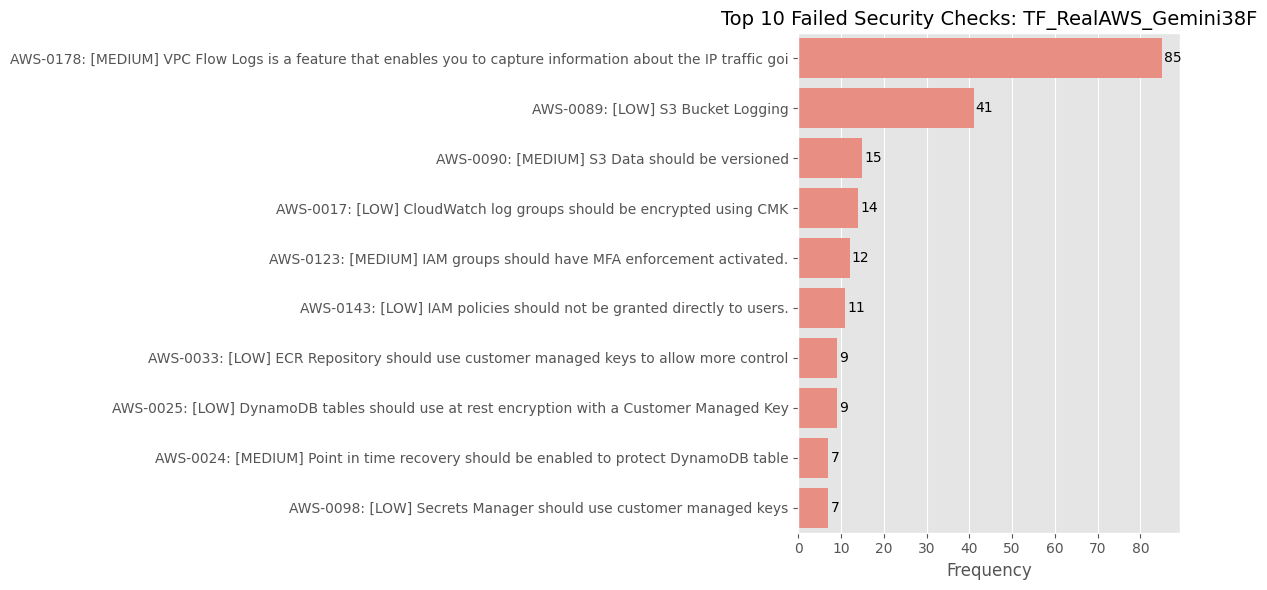

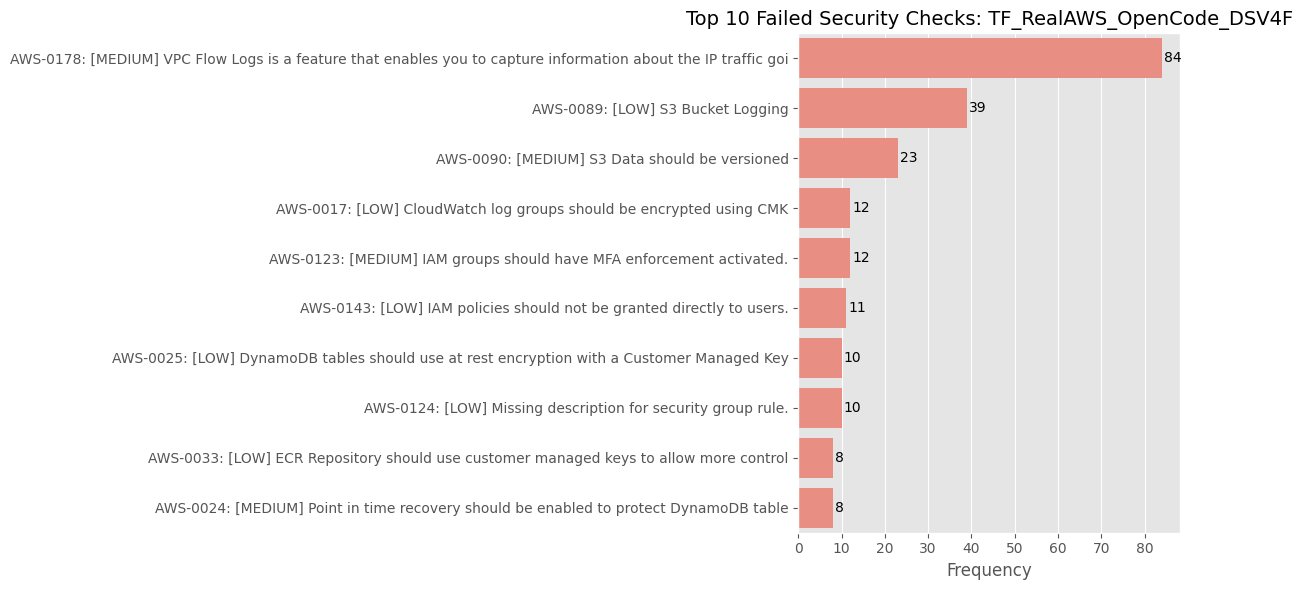

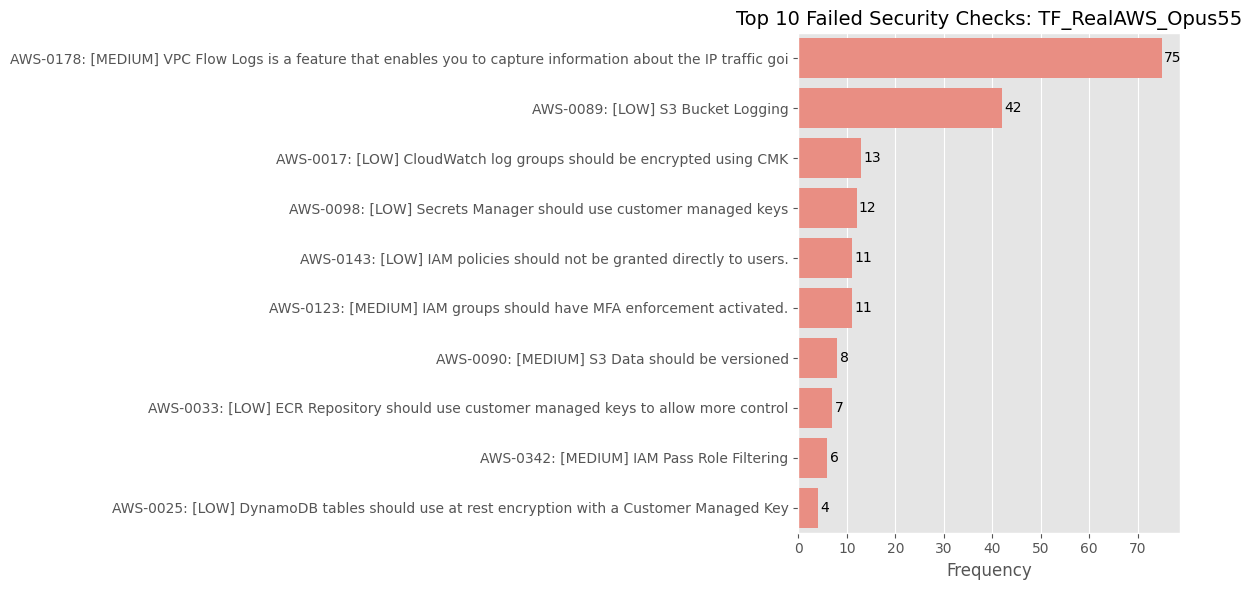

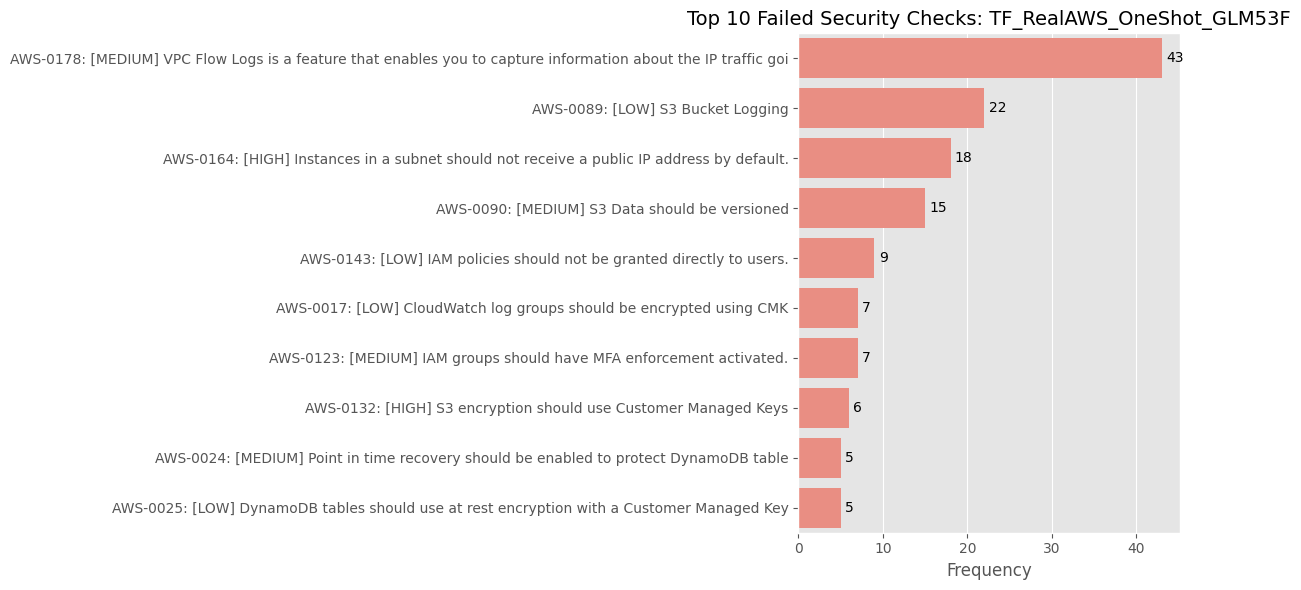

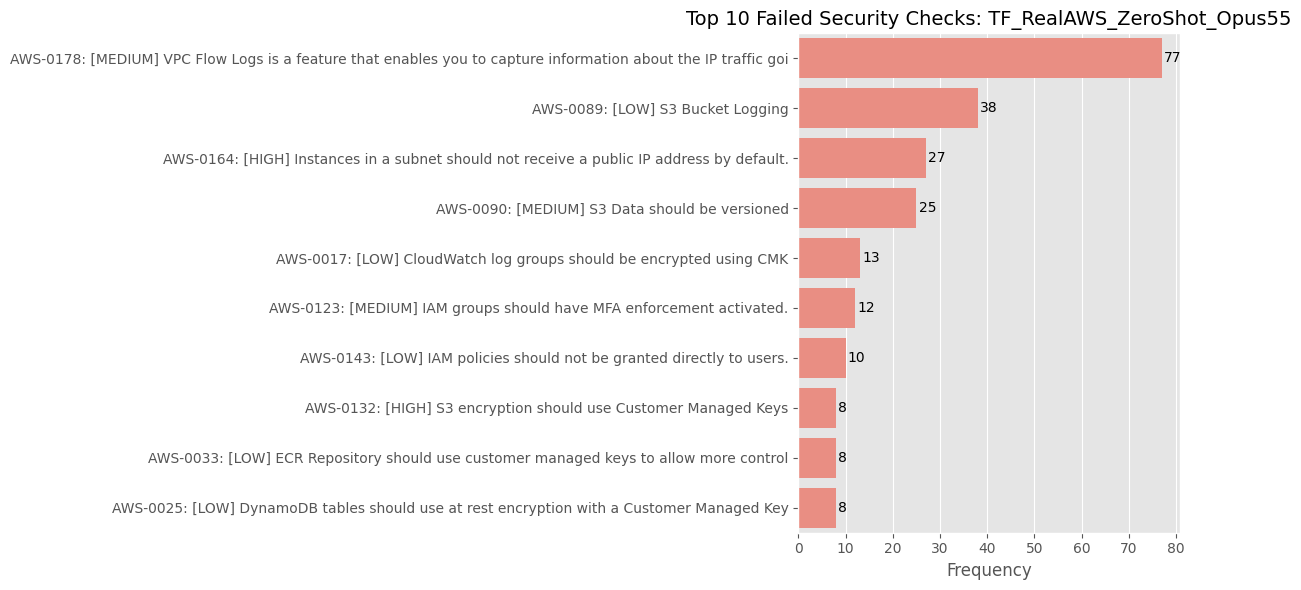

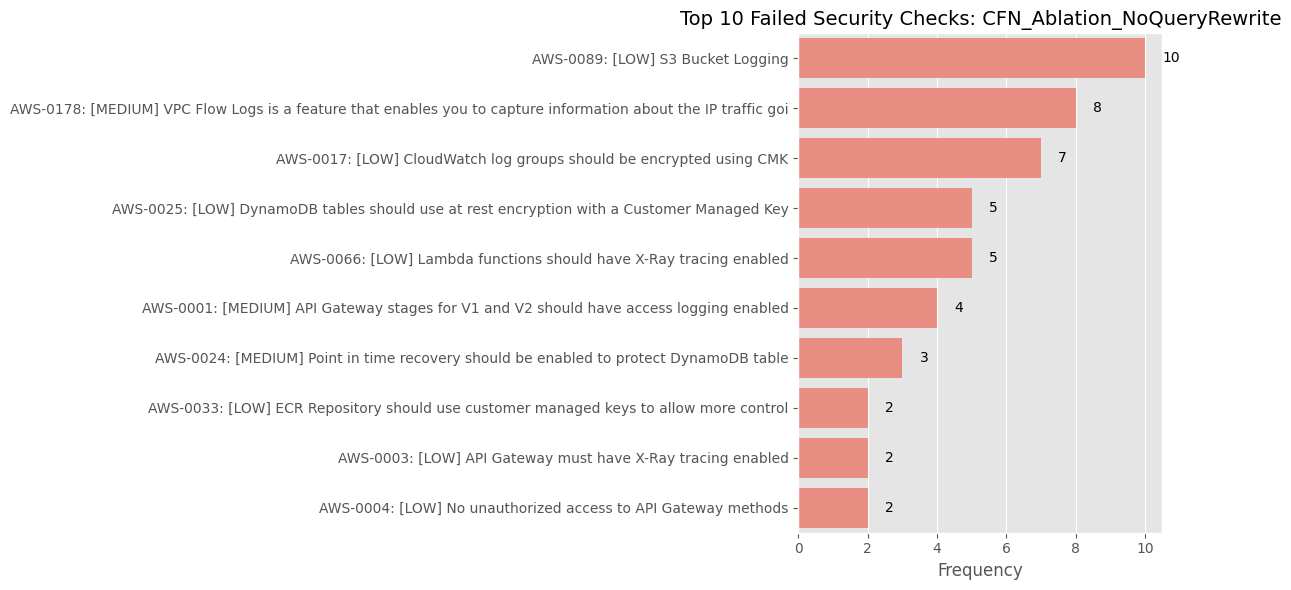

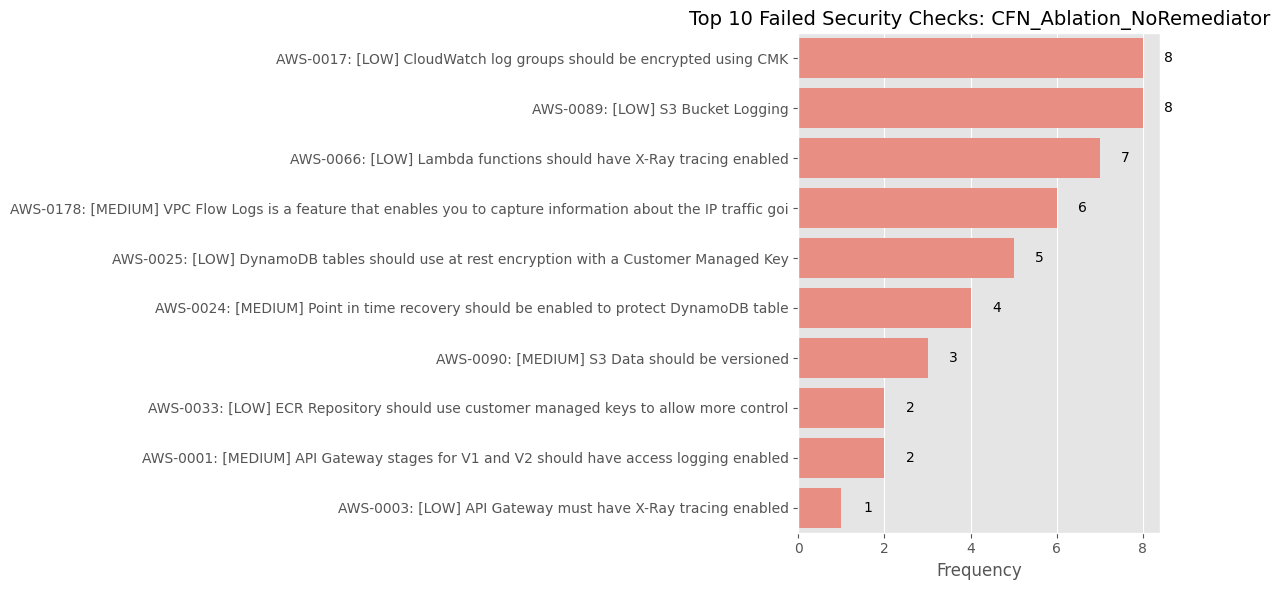

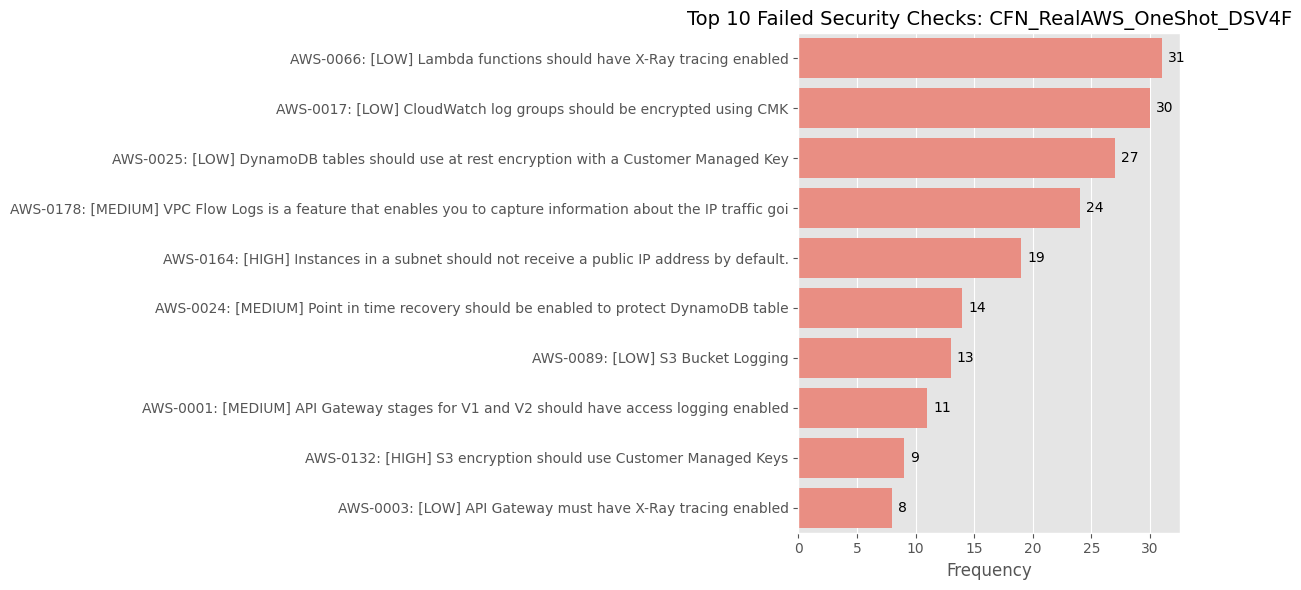

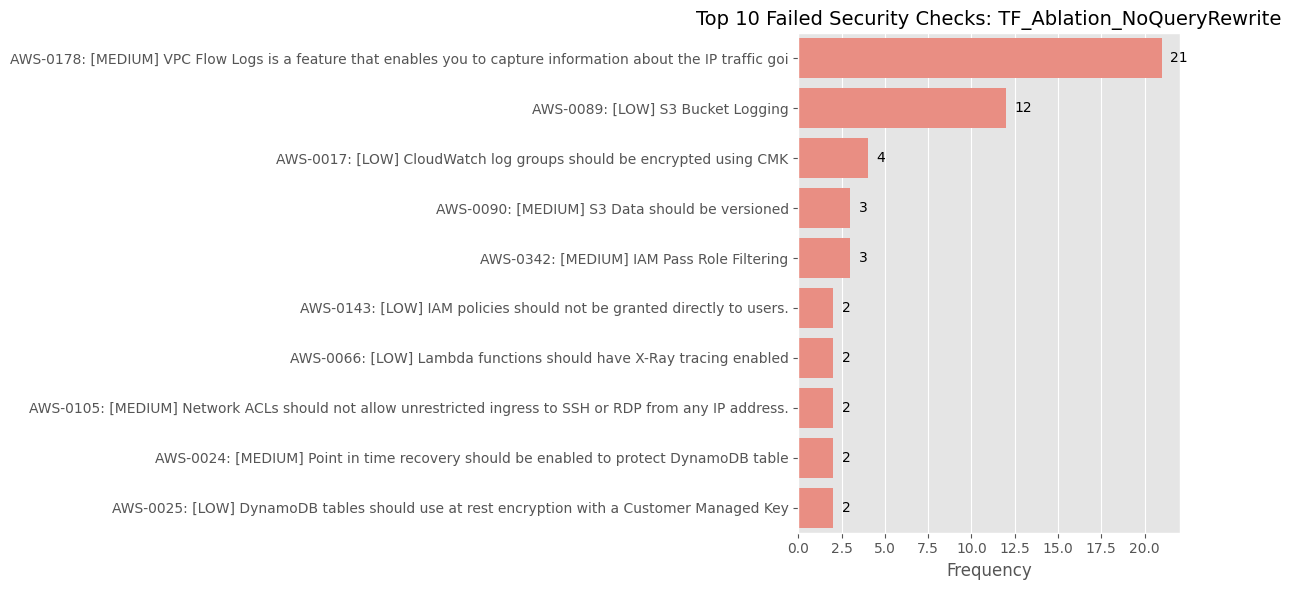

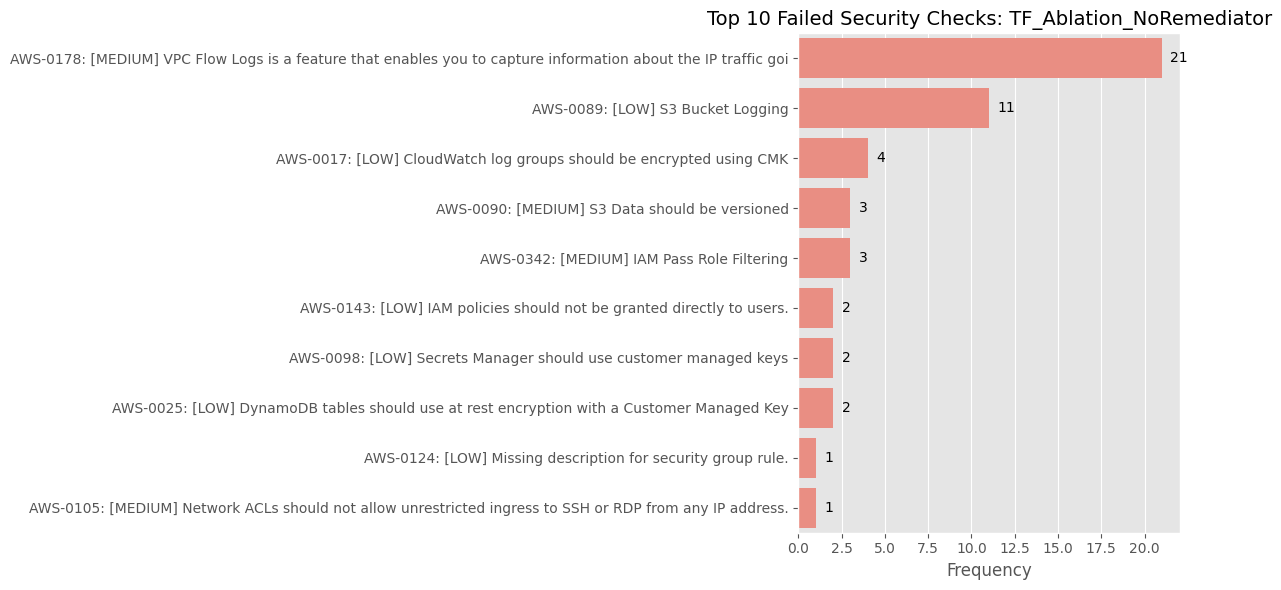

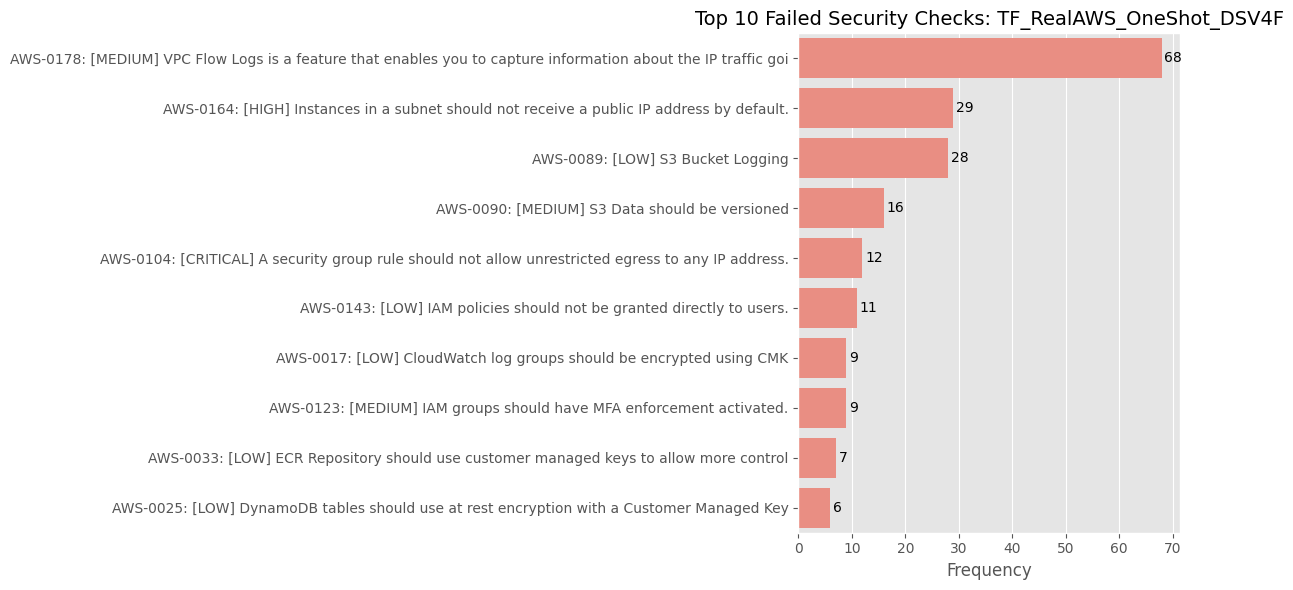

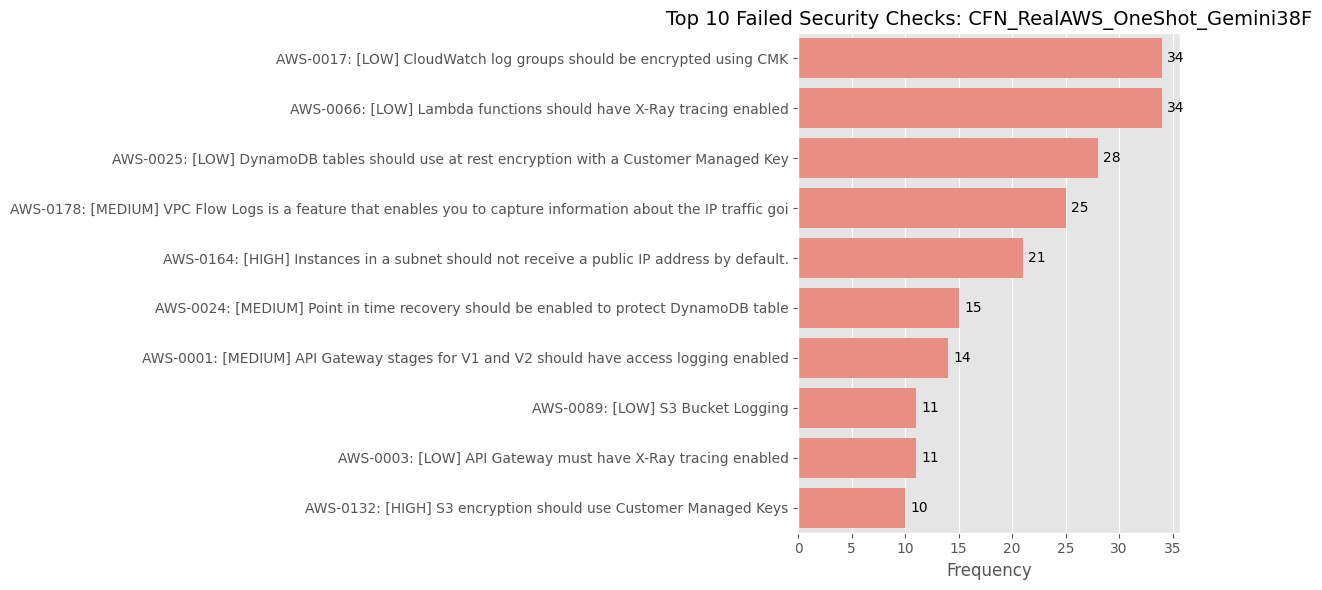

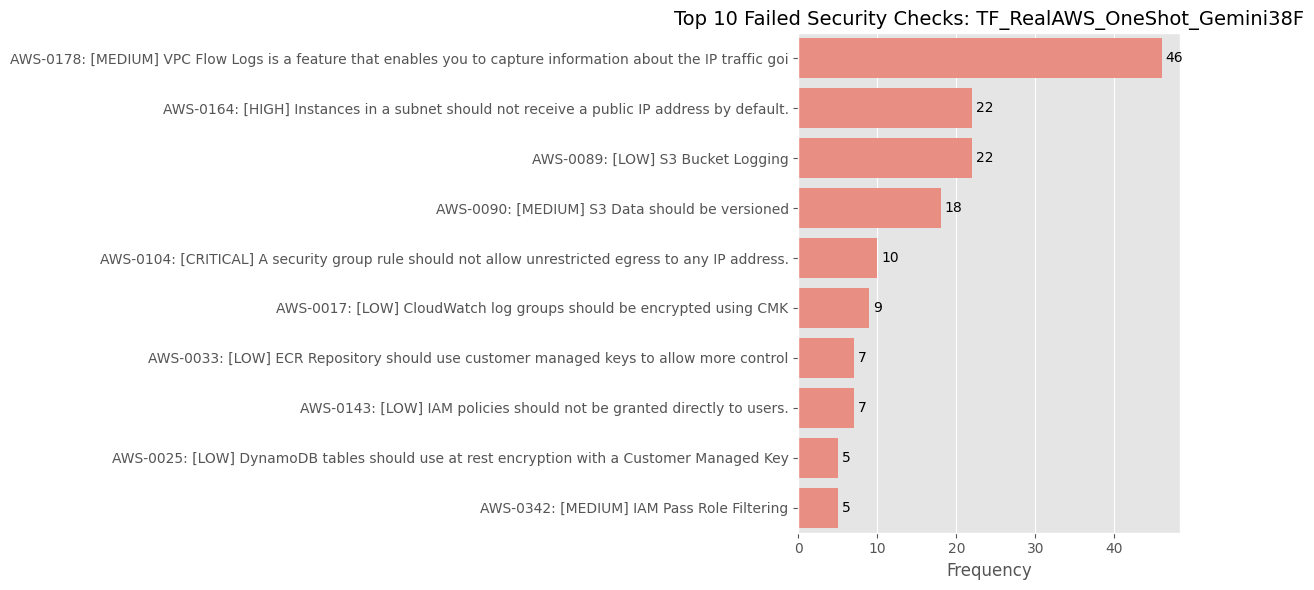

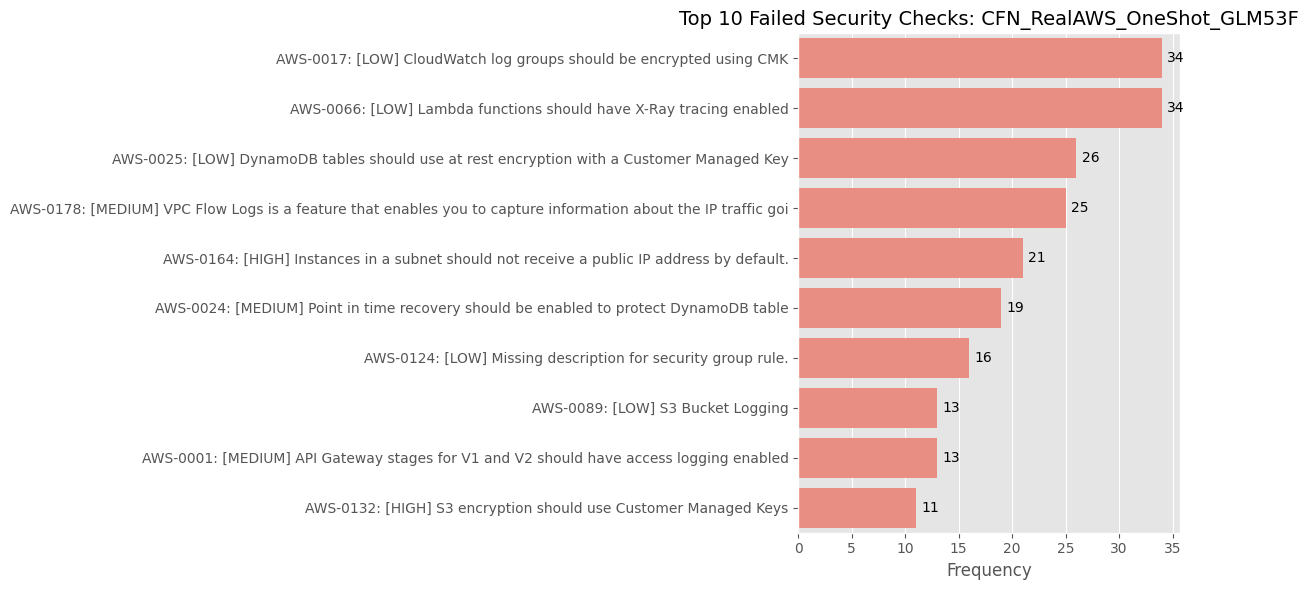

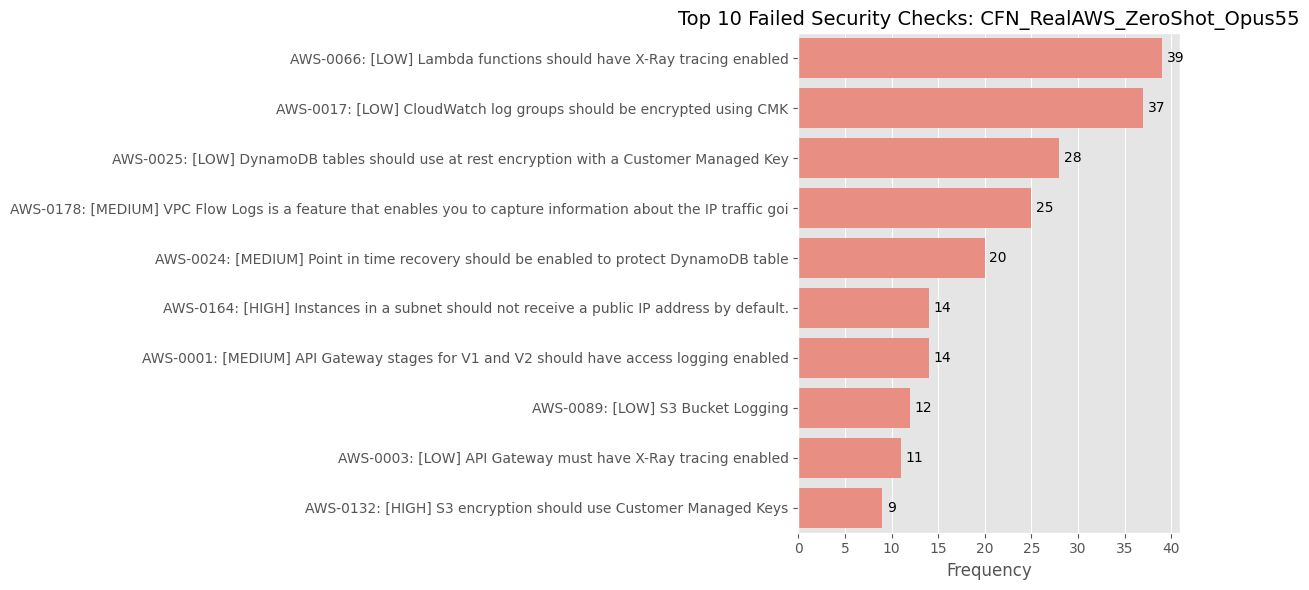

In [8]:
def get_policy_name(check_id):
    if check_id in policy_mapping:
        return f"{check_id}: {policy_mapping[check_id][:100]}"
    
    base_match = re.search(r'(AWS-\d+)', check_id)
    if base_match:
        base_id = base_match.group(1)
        if base_id in policy_mapping:
            return f"{check_id}: {policy_mapping[base_id][:100]}"
            
    return check_id

for model_name, df in merged_dataframes.items():
    failed_checks = []
    
    if 'failed_check_ids' in df.columns:
        for checks in df['failed_check_ids'].dropna():
            for check in str(checks).split(';'):
                check = check.strip()
                if check:
                    failed_checks.append(check)
    
    if failed_checks:
        counter = Counter(failed_checks)
        top_10 = counter.most_common(10)
        
        top_10_mapped = [(get_policy_name(cid), count) for cid, count in top_10]
        top_df = pd.DataFrame(top_10_mapped, columns=["Check ID & Description", "Frequency"])
        
        plt.figure(figsize=(12, 6))
        sns.barplot(data=top_df, y="Check ID & Description", x="Frequency", color="salmon")
        plt.title(f"Top 10 Failed Security Checks: {model_name}", fontsize=14)
        plt.xlabel("Frequency", fontsize=12)
        plt.ylabel("")
        
        for index, value in enumerate(top_df["Frequency"]):
            plt.text(value + 0.5, index, str(value), va='center')
            
        plt.tight_layout()
        plt.show()
    else:
        print(f"No failed checks found for model: {model_name}")

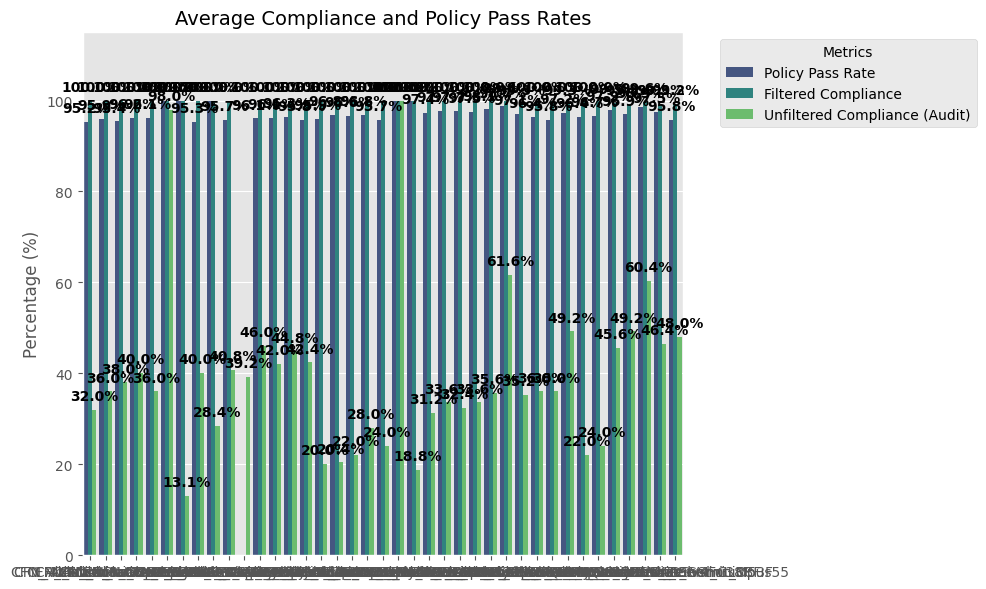

None

In [9]:
def _plot_compliance_metrics(selected_models):
    compliance_stats = []

    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        if 'scenario_policy_pass_rate' in df.columns:
            avg_policy_pass = df['scenario_policy_pass_rate'].mean() * 100
        else:
            avg_policy_pass = df['Policy Pass Rate'].mean() * 100

        if 'filtered_compliance_rate' in df.columns:
            avg_filtered_compliance = df['filtered_compliance_rate'].mean() * 100
        else:
            avg_filtered_compliance = 0

        if 'trivy_passed' in df.columns:
            avg_unfiltered_compliance = (df['trivy_passed'] == True).mean() * 100
        else:
            avg_unfiltered_compliance = 0

        compliance_stats.extend([
            {'Model': model_name, 'Metric': 'Policy Pass Rate', 'Rate (%)': avg_policy_pass},
            {'Model': model_name, 'Metric': 'Filtered Compliance', 'Rate (%)': avg_filtered_compliance},
            {'Model': model_name, 'Metric': 'Unfiltered Compliance (Audit)', 'Rate (%)': avg_unfiltered_compliance}
        ])

    compliance_df = pd.DataFrame(compliance_stats)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=compliance_df, x='Model', y='Rate (%)', hue='Metric', palette='viridis')

    plt.title('Average Compliance and Policy Pass Rates', fontsize=14)
    plt.ylabel('Percentage (%)', fontsize=12)
    plt.xlabel('')
    plt.ylim(0, 115)

    for p in plt.gca().patches:
        height = p.get_height()
        if pd.notna(height) and height > 0:
            plt.gca().text(
                p.get_x() + p.get_width() / 2.,
                height + 1.5,
                f'{height:.1f}%',
                ha='center',
                va='bottom',
                fontsize=10,
                fontweight='bold'
            )

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Metrics")
    plt.tight_layout()
    plt.show()

_out_compliance_metrics = widgets.interactive_output(
    _plot_compliance_metrics, {'selected_models': model_selector}
)
display(_out_compliance_metrics)

📊 Per-Severity Detailed Summary:
                            Model Severity  Evaluated Checks  Passed Checks  Failed Checks  Pass Rate (%)
              CFN_Ablation_IaCGOD Critical               108            108              0     100.000000
              CFN_Ablation_IaCGOD     High               489            488              1      99.795501
              CFN_Ablation_IaCGOD   Medium               708            678             30      95.762712
              CFN_Ablation_IaCGOD      Low               330            265             65      80.303030
          CFN_Ablation_NoDenseRAG Critical                92             92              0     100.000000
          CFN_Ablation_NoDenseRAG     High               464            463              1      99.784483
          CFN_Ablation_NoDenseRAG   Medium               700            679             21      97.000000
          CFN_Ablation_NoDenseRAG      Low               312            258             54      82.692308
          CFN



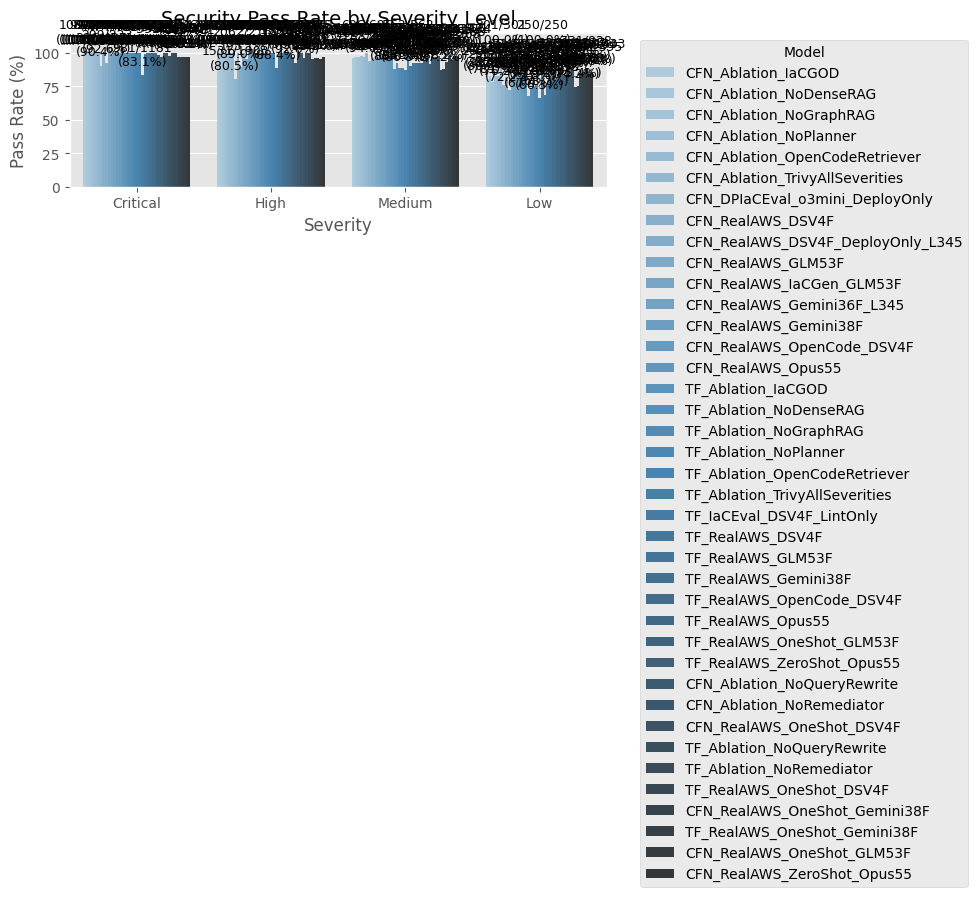

None

In [10]:
def _plot_severity_evaluated_vs_passed(selected_models):
    severities = ['critical', 'high', 'medium', 'low']
    severity_metrics = []

    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        for sev in severities:
            eval_col = f'severity_{sev}_eval'
            pass_col = f'severity_{sev}_passed'
            fail_col = f'severity_{sev}_failed'
            legacy_col = f'severity_{sev}'

            if eval_col in df.columns and pass_col in df.columns:
                total_eval = int(df[eval_col].sum())
                total_passed = int(df[pass_col].sum())
                total_failed = int(df[fail_col].sum()) if fail_col in df.columns else (total_eval - total_passed)

            elif legacy_col in df.columns:
                total_failed = int(df[legacy_col].sum())
                total_eval = total_failed
                total_passed = 0
            else:
                continue

            pass_rate = (total_passed / total_eval * 100) if total_eval > 0 else 0.0

            severity_metrics.append({
                'Model': model_name,
                'Severity': sev.capitalize(),
                'Evaluated Checks': total_eval,
                'Passed Checks': total_passed,
                'Failed Checks': total_failed,
                'Pass Rate (%)': pass_rate
            })

    if severity_metrics:
        sev_summary_df = pd.DataFrame(severity_metrics)

        print("📊 Per-Severity Detailed Summary:")
        print(sev_summary_df[['Model', 'Severity', 'Evaluated Checks', 'Passed Checks', 'Failed Checks', 'Pass Rate (%)']].to_string(index=False))
        print("\n" + "─"*75)

        melted_counts = sev_summary_df.melt(
            id_vars=['Model', 'Severity'],
            value_vars=['Evaluated Checks', 'Passed Checks'],
            var_name='Status',
            value_name='Check Count'
        )

        g1 = sns.catplot(
            data=melted_counts, kind="bar",
            x="Severity", y="Check Count", hue="Status", col="Model",
            palette=["#4C72B0", "#55A868"], height=5, aspect=1.2
        )
        g1.set_axis_labels("Severity Level", "Total Count of Checks")
        g1.fig.suptitle('Evaluated vs. Passed Checks by Severity Level', fontsize=16, y=1.05)

        for ax in g1.axes.flat:
            for p in ax.patches:
                height = p.get_height()
                if pd.notna(height) and height > 0:
                    ax.text(p.get_x() + p.get_width() / 2., height + (ax.get_ylim()[1] * 0.01),
                            f'{int(height)}', ha='center', va='bottom', fontsize=9, fontweight='bold')

        plt.show()

        plt.figure(figsize=(10, 6))
        ax2 = sns.barplot(data=sev_summary_df, x='Severity', y='Pass Rate (%)', hue='Model', palette='Blues_d')

        plt.title('Security Pass Rate by Severity Level', fontsize=14)
        plt.ylabel('Pass Rate (%)')
        plt.ylim(0, 115)
        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')

        for i, container in enumerate(ax2.containers):
            model_name = ax2.get_legend().get_texts()[i].get_text()

            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or height == 0:
                    continue

                sev_name = ax2.get_xticklabels()[j].get_text()
                row = sev_summary_df[(sev_summary_df['Model'] == model_name) & (sev_summary_df['Severity'] == sev_name)]

                if not row.empty:
                    passed = row['Passed Checks'].values[0]
                    eval_cnt = row['Evaluated Checks'].values[0]
                    rate = row['Pass Rate (%)'].values[0]

                    label_text = f"{passed}/{eval_cnt}\n({rate:.1f}%)"
                    ax2.annotate(label_text,
                                 (p.get_x() + p.get_width() / 2., height),
                                 ha='center', va='bottom',
                                 xytext=(0, 5), textcoords='offset points',
                                 fontsize=9)

        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No severity evaluation columns (`severity_<level>_eval`, `severity_<level>_passed`) found in the dataset.")

_out_severity_evaluated_vs_passed = widgets.interactive_output(
    _plot_severity_evaluated_vs_passed, {'selected_models': model_selector}
)
display(_out_severity_evaluated_vs_passed)

📋 SUMMARY: Deployment Outcomes & Blockers
                            Model                      Outcome                             Root Cause Detail  Count
              CFN_Ablation_IaCGOD        Deployed Successfully                                           N/A     49
              CFN_Ablation_IaCGOD Skipped (Pre-Deploy Failure)                   Blocked by Security (Trivy)      1
          CFN_Ablation_NoDenseRAG        Deployed Successfully                                           N/A     49
          CFN_Ablation_NoDenseRAG Skipped (Pre-Deploy Failure)                   Blocked by Security (Trivy)      1
          CFN_Ablation_NoGraphRAG        Deployed Successfully                                           N/A     50
           CFN_Ablation_NoPlanner       Deploy Execution Error                        Runtime Target Failure      1
           CFN_Ablation_NoPlanner        Deployed Successfully                                           N/A     48
           CFN_Ablation_NoPlan

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8525/1238326339.py:84: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


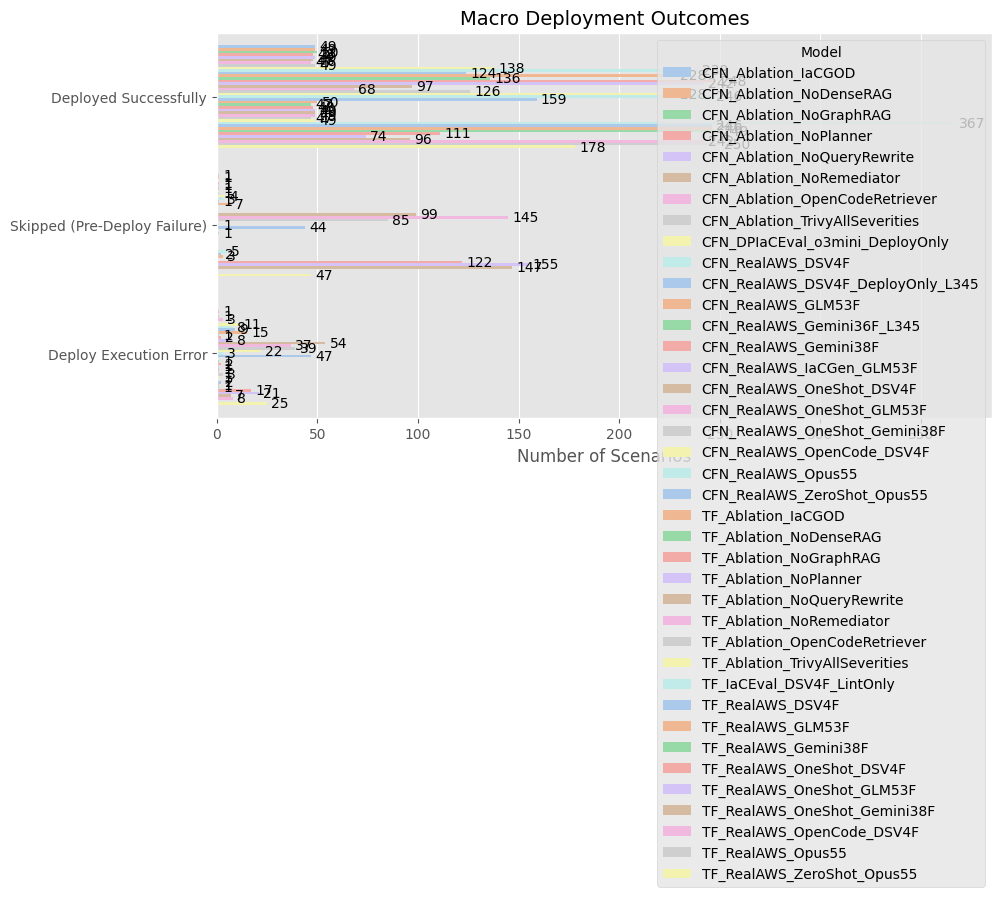

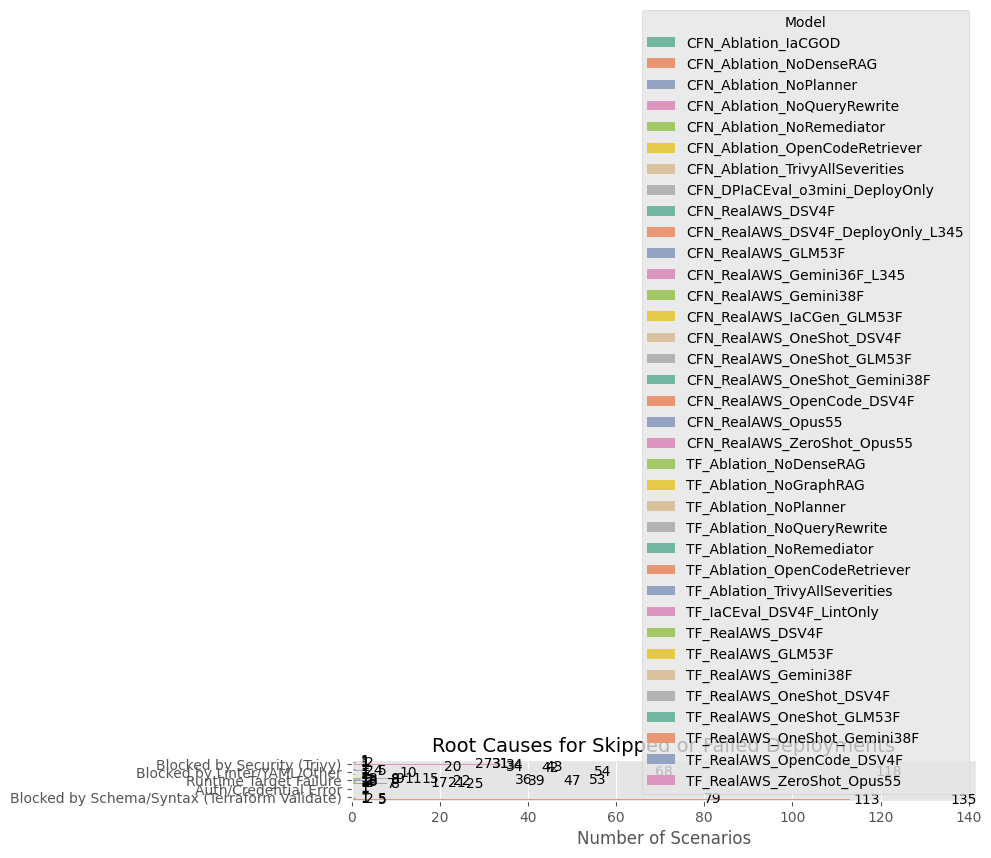

None

In [11]:
def _plot_deployment_errors_root_cause(selected_models):
    deploy_analytics = []
    raw_errors = []

    dfs = {m: merged_dataframes[m] for m in selected_models}
    for model_name, df in dfs.items():
        deploy_pass_col = 'deploy_passed' if 'deploy_passed' in df.columns else 'final_validation_passed'
        deploy_err_col = 'deploy_error_message'
        tf_val_err_col = 'latest_error_terraform-validate'
        trivy_err_col = 'latest_error_trivy'

        for idx, row in df.iterrows():
            dep_pass = row.get(deploy_pass_col, True)
            err_msg = str(row.get(deploy_err_col, '')).strip() if pd.notna(row.get(deploy_err_col)) else ''
            tf_err = str(row.get(tf_val_err_col, '')).strip() if pd.notna(row.get(tf_val_err_col)) else ''
            trivy_err = str(row.get(trivy_err_col, '')).strip() if pd.notna(row.get(trivy_err_col)) else ''

            if dep_pass and not err_msg:
                category = 'Deployed Successfully'
                detail = 'N/A'

            elif 'Skipped' in err_msg or (dep_pass and err_msg):
                category = 'Skipped (Pre-Deploy Failure)'
                if trivy_err and trivy_err != 'None':
                    detail = 'Blocked by Security (Trivy)'
                elif tf_err and tf_err != 'None':
                    detail = 'Blocked by Schema/Syntax (Terraform Validate)'
                else:
                    detail = 'Blocked by Linter/YAML/Other'

            else:
                category = 'Deploy Execution Error'
                if '403' in err_msg or 'UnrecognizedClientException' in err_msg:
                    detail = 'Auth/Credential Error'
                elif 'LocalStack' in err_msg:
                    detail = 'LocalStack Emulation Error'
                else:
                    detail = 'Runtime Target Failure'

                raw_errors.append(f"Model: {model_name} | Row {idx} | Msg: {err_msg[:150]}...")

            deploy_analytics.append({
                'Model': model_name,
                'Outcome': category,
                'Root Cause Detail': detail
            })

    analytics_df = pd.DataFrame(deploy_analytics)

    if not analytics_df.empty:
        print("📋 SUMMARY: Deployment Outcomes & Blockers")
        print("=" * 65)
        summary_table = analytics_df.groupby(['Model', 'Outcome', 'Root Cause Detail']).size().reset_index(name='Count')
        print(summary_table.to_string(index=False))

        if raw_errors:
            print("\n⚠️ RAW DEPLOYMENT EXECUTION ERRORS (Runtime Failures):")
            print("=" * 65)
            for err in raw_errors:
                print(f" - {err}")

        macro_counts = analytics_df.groupby(['Model', 'Outcome']).size().reset_index(name='Count')

        plt.figure(figsize=(10, 5))
        g1 = sns.barplot(data=macro_counts, x='Count', y='Outcome', hue='Model', palette='pastel')
        plt.title('Macro Deployment Outcomes', fontsize=14)
        plt.xlabel('Number of Scenarios')
        plt.ylabel('')

        for container in g1.containers:
            g1.bar_label(container, padding=3, fontsize=10)
        plt.tight_layout()
        plt.show()

        failed_df = analytics_df[analytics_df['Outcome'] != 'Deployed Successfully']

        if not failed_df.empty:
            micro_counts = failed_df.groupby(['Model', 'Root Cause Detail']).size().reset_index(name='Count')

            plt.figure(figsize=(10, 5))
            g2 = sns.barplot(data=micro_counts, x='Count', y='Root Cause Detail', hue='Model', palette='Set2')
            plt.title('Root Causes for Skipped or Failed Deployments', fontsize=14)
            plt.xlabel('Number of Scenarios')
            plt.ylabel('')

            for container in g2.containers:
                g2.bar_label(container, padding=3, fontsize=10)
            plt.tight_layout()
            plt.show()
        else:
            print("\n🎉 Incredible! No deployment errors or skips found across any model runs.")

_out_deployment_errors_root_cause = widgets.interactive_output(
    _plot_deployment_errors_root_cause, {'selected_models': model_selector}
)
display(_out_deployment_errors_root_cause)